<a href="https://colab.research.google.com/github/ChronosXV/Metodologia_grupo2/blob/noelia_modelado/Metodologia_1_Grupo_2_Modelado_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Trabajo Práctico Final

**Materia:**

Metodología de la Investigación

**Alumnos:**

- Gisela Martínez
- Noelia Cualina
- José Leonardo Carabajal
- Javier Carabajal


**Objetivo:**

Desarrollar y evaluar modelos de Machine Learning para predecir niveles de demanda en la red de subtes de CABA.

Período de estudio: 2017–2021.



Enfoque: cuantitativo, descriptivo y predictivo.



Metodología: CRISP-DM.



Variable objetivo: nivel_demanda, con categorías baja, media y alta.



Variable base para construir el objetivo: pax_total.



Variables predictoras: línea, estación, franja horaria, año, mes, día de la semana y condición de día hábil.



Evaluación: accuracy, precision, recall, F1-score y matriz de confusión.

### 1. Introducción y objetivo del modelado

El presente trabajo constituye la continuación del análisis exploratorio y la preparación de datos realizados sobre los registros históricos de pasajeros de la red de subterráneos de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021.

En esta etapa se propone desarrollar y evaluar modelos de Machine Learning que permitan clasificar y predecir niveles de demanda de pasajeros, utilizando información temporal y espacial disponible en los registros históricos.

Para ello, se utilizará el conjunto de datos previamente procesado y agrupado por fecha, línea, estación y franja horaria, tomando como referencia la cantidad total de pasajeros registrados (pax_total).

A partir de esta variable se construirán tres categorías de demanda: baja, media y alta, que constituirán la variable objetivo (nivel_demanda) del problema de clasificación supervisada.

Los modelos utilizarán características como la línea, la estación, la franja horaria y variables temporales derivadas de la fecha. La cantidad total de pasajeros no será incorporada como variable predictora, dado que se utilizará para construir la variable objetivo.

Se compararán distintos algoritmos de clasificación mediante métricas de evaluación apropiadas, prestando especial atención a la identificación de situaciones de alta demanda.

Asimismo, se contempla la aplicación de técnicas de aprendizaje no supervisado como análisis complementario, con el propósito de identificar posibles agrupamientos en los patrones de demanda.

El desarrollo seguirá las etapas de modelado y evaluación de la metodología CRISP-DM, buscando obtener resultados reproducibles que permitan contrastar la hipótesis planteada y formular recomendaciones basadas en evidencia cuantitativa.
####

**Hipótesis de investigación**

Los episodios de alta demanda en la red de subtes de CABA durante el período 2017–2021 no se distribuyen de manera uniforme, sino que presentan patrones asociados a factores temporales y espaciales. Se espera que la probabilidad de registrar niveles elevados de demanda varíe según la estación, la línea, el día de la semana y la franja horaria, permitiendo identificar y predecir situaciones de alta demanda a partir de estas características.


### 2. Importación de librerías y carga del dataset procesado.

En esta sección se importan las bibliotecas necesarias para el procesamiento de datos, la construcción de modelos de Machine Learning y la evaluación de resultados. Posteriormente, se carga el conjunto de datos consolidado durante la etapa de preparación, que servirá como base para el modelado predictivo.

In [2]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np
import os

# Visualización de resultados
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score
from sklearn.base import clone
from sklearn.metrics import recall_score

# Modelos de clasificación supervisada
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluación de modelos
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Aprendizaje no supervisado
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Acceso a Google Drive
from google.colab import drive

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [3]:
# Montar Google Drive
drive.mount("/content/drive")

# Definir la ruta del dataset procesado
ruta_carpeta = "/content/drive/MyDrive/Datos_csv/"
ruta_limpios = os.path.join(ruta_carpeta, "datos_limpios")

ruta_dataset = os.path.join(
    ruta_limpios,
    "historico_2017_2021_dim.parquet"
)

# Cargar el dataset consolidado
df = pd.read_parquet(ruta_dataset)

# Verificar la carga
print("Dataset cargado correctamente.")
print(f"Cantidad de registros: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}")

Mounted at /content/drive
Dataset cargado correctamente.
Cantidad de registros: 653,619
Cantidad de columnas: 6


In [4]:
display(df.head())

,fecha,linea,estacion,franja_horaria_num,franja_horaria,pax_total
0,2017-11-27,D,9 DE JULIO,5,Noche,535.0
1,2017-11-28,D,9 DE JULIO,1,Madrugada,9.0
2,2017-11-28,D,9 DE JULIO,2,Pico mañana,1922.0
3,2017-11-28,D,9 DE JULIO,3,Media mañana,4345.0
4,2017-11-29,D,9 DE JULIO,2,Pico mañana,1722.0


In [5]:
# Verificar estructura y tipos de datos del dataset
print("Información general del dataset:")
df.info()

print("\nValores nulos por columna:")
print(df.isnull().sum())

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653619 entries, 0 to 653618
Data columns (total 6 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   fecha               653619 non-null  object 
 1   linea               653619 non-null  object 
 2   estacion            653619 non-null  object 
 3   franja_horaria_num  653619 non-null  int32  
 4   franja_horaria      653619 non-null  object 
 5   pax_total           653619 non-null  float64
dtypes: float64(1), int32(1), object(4)
memory usage: 27.4+ MB

Valores nulos por columna:
fecha                 0
linea                 0
estacion              0
franja_horaria_num    0
franja_horaria        0
pax_total             0
dtype: int64


### 3. Construcción de variables predictoras.

En esta etapa se preparan las variables que serán utilizadas como características de entrada para los modelos de Machine Learning.

A partir del conjunto de datos consolidado, se conservarán las variables espaciales y temporales disponibles, como la línea, la estación y la franja horaria. Además, se construirán nuevas variables a partir de la fecha, con el propósito de representar patrones asociados al comportamiento de la demanda de pasajeros.

Las variables derivadas serán:

*  Año: permite identificar variaciones de demanda entre los distintos años del período analizado.
*  Mes: permite representar posibles patrones estacionales.
*  Día de la semana: permite identificar diferencias de demanda entre lunes y domingo.
*  Fin de semana: permite distinguir sábados y domingos del resto de los días.


La variable pax_total se conservará únicamente para la posterior construcción de la variable objetivo nivel_demanda, correspondiente a las categorías baja, media y alta.

De esta manera, se busca que los modelos aprendan relaciones entre las características temporales y espaciales y los niveles de demanda, evitando incorporar directamente como predictor la cantidad de pasajeros que se desea clasificar.

In [6]:
# Crear una copia del dataset para el modelado
df_modelo = df.copy()

# Convertir la columna fecha a tipo datetime
df_modelo["fecha"] = pd.to_datetime(
    df_modelo["fecha"],
    format="%Y-%m-%d",
    errors="raise"
)

# Construir variables temporales
df_modelo["anio"] = df_modelo["fecha"].dt.year
df_modelo["mes"] = df_modelo["fecha"].dt.month
df_modelo["dia_semana"] = df_modelo["fecha"].dt.dayofweek

# Identificar fines de semana: sábado (5) y domingo (6)
df_modelo["fin_semana"] = (
    df_modelo["dia_semana"] >= 5
).astype(int)

# Visualizar los primeros registros
display(df_modelo.head())

print("\nDimensiones del dataset:", df_modelo.shape)

,fecha,linea,estacion,franja_horaria_num,franja_horaria,pax_total,anio,mes,dia_semana,fin_semana
0,2017-11-27,D,9 DE JULIO,5,Noche,535.0,2017,11,0,0
1,2017-11-28,D,9 DE JULIO,1,Madrugada,9.0,2017,11,1,0
2,2017-11-28,D,9 DE JULIO,2,Pico mañana,1922.0,2017,11,1,0
3,2017-11-28,D,9 DE JULIO,3,Media mañana,4345.0,2017,11,1,0
4,2017-11-29,D,9 DE JULIO,2,Pico mañana,1722.0,2017,11,2,0



Dimensiones del dataset: (653619, 10)


In [7]:
# Seleccionar las variables predictoras
variables_predictoras = [
    "linea",
    "estacion",
    "franja_horaria_num",
    "anio",
    "mes",
    "dia_semana"
]

# Crear el conjunto de características
X = df_modelo[variables_predictoras].copy()

# Verificar las variables seleccionadas
print("Variables predictoras:")
print(X.columns.tolist())

print("\nDimensiones de X:", X.shape)

display(X.head())

Variables predictoras:
['linea', 'estacion', 'franja_horaria_num', 'anio', 'mes', 'dia_semana']

Dimensiones de X: (653619, 6)


,linea,estacion,franja_horaria_num,anio,mes,dia_semana
0,D,9 DE JULIO,5,2017,11,0
1,D,9 DE JULIO,1,2017,11,1
2,D,9 DE JULIO,2,2017,11,1
3,D,9 DE JULIO,3,2017,11,1
4,D,9 DE JULIO,2,2017,11,2


### 4. Definición de la variable objetivo nivel_demanda.

Para el desarrollo de los modelos de clasificación supervisada, se construirá una variable objetivo denominada nivel_demanda, que permitirá clasificar los registros históricos de pasajeros en tres categorías: baja, media y alta demanda.

Esta clasificación se realizará a partir de la variable pax_total, que representa la cantidad total de pasajeros registrada para cada combinación de fecha, línea, estación y franja horaria.

Se propone utilizar un criterio basado en cuantiles, dividiendo la distribución de pasajeros en tres grupos mediante los percentiles 33,33 y 66,67. Este procedimiento permitirá establecer umbrales reproducibles a partir de la distribución observada.

Para evitar fugas de información, los umbrales definitivos se calcularán exclusivamente sobre el conjunto de entrenamiento, después de realizar la separación temporal de los datos. Posteriormente, se aplicarán los mismos límites al conjunto de prueba.

La variable pax_total no se utilizará como característica predictora, ya que constituye la información a partir de la cual se define la variable objetivo.

Es importante señalar que los niveles establecidos representan categorías relativas de demanda de pasajeros, utilizadas como aproximación para identificar situaciones potenciales de congestión, y no mediciones directas de ocupación o saturación de las estaciones.

In [8]:
# Separación temporal preliminar del dataset
# Entrenamiento: 2017 a 2020
# Prueba: 2021

df_train = df_modelo[
    df_modelo["anio"] <= 2020
].copy()

df_test = df_modelo[
    df_modelo["anio"] == 2021
].copy()

# Verificar la cantidad de registros
print("Registros de entrenamiento:", len(df_train))
print("Registros de prueba:", len(df_test))

print("\nDistribución porcentual:")
print(
    f"Entrenamiento: {len(df_train) / len(df_modelo) * 100:.2f}%"
)

Registros de entrenamiento: 541247
Registros de prueba: 112372

Distribución porcentual:
Entrenamiento: 82.81%


In [9]:
# Calcular los cuantiles únicamente con datos de entrenamiento
cuantiles = df_train["pax_total"].quantile([1/3, 2/3])

# Mostrar los valores obtenidos
print("Cuantiles de pax_total (2017-2020):")
print(cuantiles)

Cuantiles de pax_total (2017-2020):
0.333333     354.0
0.666667    1825.0
Name: pax_total, dtype: float64


**Interpretación de los cuantiles obtenidos**

A partir de los registros correspondientes al conjunto de entrenamiento (2017–2020), se calcularon los percentiles 33,33 y 66,67 de la variable `pax_total`, obteniendo los siguientes resultados:

| Percentil | Pasajeros | Interpretación |
|---|---:|---|
| 33,33 % | 354 | Límite entre demanda baja y media |
| 66,67 % | 1.825 | Límite entre demanda media y alta |

Estos valores permiten establecer tres niveles de demanda:

- **Demanda baja:** registros con hasta 354 pasajeros.
- **Demanda media:** registros con más de 354 y hasta 1.825 pasajeros.
- **Demanda alta:** registros con más de 1.825 pasajeros.

Los umbrales se definieron utilizando exclusivamente los datos de entrenamiento y se aplicarán posteriormente al conjunto de prueba (2021), manteniendo el mismo criterio de clasificación.

Es importante destacar que estas categorías representan niveles relativos de demanda según la distribución histórica de pasajeros, y no umbrales operativos de congestión establecidos por la capacidad de las estaciones.

In [10]:
# Obtener los umbrales calculados con entrenamiento
umbral_bajo = cuantiles.loc[1/3]
umbral_alto = cuantiles.loc[2/3]

# Función para clasificar la demanda de pasajeros
def clasificar_demanda(pasajeros):
    """
    Clasifica la cantidad de pasajeros en tres niveles de demanda:
    Baja, Media o Alta.

    Utiliza los umbrales calculados a partir de los cuantiles
    33,33 % y 66,67 % del conjunto de entrenamiento (2017-2020).

    Parámetros:
        pasajeros: cantidad total de pasajeros del registro.

    Retorna:
        str: categoría de demanda correspondiente.
    """
    if pasajeros <= umbral_bajo:
        return "Baja"
    elif pasajeros <= umbral_alto:
        return "Media"
    else:
        return "Alta"

# Aplicar los mismos umbrales a entrenamiento y prueba
df_train["nivel_demanda"] = (
    df_train["pax_total"].apply(clasificar_demanda)
)

df_test["nivel_demanda"] = (
    df_test["pax_total"].apply(clasificar_demanda)
)

# Verificar la distribución de las categorías
print("Distribución de demanda - Entrenamiento:")
print(df_train["nivel_demanda"].value_counts())

print("\nDistribución de demanda - Prueba:")
print(df_test["nivel_demanda"].value_counts())

Distribución de demanda - Entrenamiento:
nivel_demanda
Media    180453
Baja     180441
Alta     180353
Name: count, dtype: int64

Distribución de demanda - Prueba:
nivel_demanda
Baja     54101
Media    42326
Alta     15945
Name: count, dtype: int64


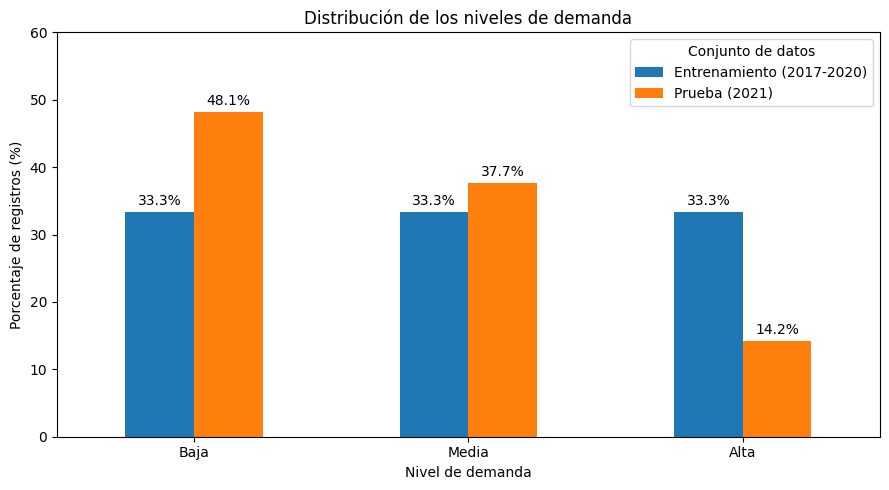

In [11]:
# Comparar la distribución porcentual de los niveles de demanda
orden_niveles = ["Baja", "Media", "Alta"]

# Calcular porcentajes por conjunto
porcentaje_train = (
    df_train["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden_niveles)
    .mul(100)
)

porcentaje_test = (
    df_test["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden_niveles)
    .mul(100)
)

# Preparar los datos para el gráfico
df_distribucion = pd.DataFrame({
    "Entrenamiento (2017-2020)": porcentaje_train,
    "Prueba (2021)": porcentaje_test
})

# Visualizar la comparación
ax = df_distribucion.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Distribución de los niveles de demanda")
ax.set_xlabel("Nivel de demanda")
ax.set_ylabel("Porcentaje de registros (%)")
ax.legend(title="Conjunto de datos")

# Mostrar porcentajes sobre cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=3)

plt.ylim(0, 60)
plt.tight_layout()
plt.show()


**Interpretación de la distribución de los niveles de demanda**

A partir de los umbrales definidos mediante los cuantiles del conjunto de entrenamiento, se construyó la variable objetivo nivel_demanda, clasificando los registros en tres categorías: baja, media y alta.

En el conjunto de entrenamiento (2017–2020), las categorías presentan una distribución prácticamente equilibrada, con aproximadamente un tercio de los registros en cada nivel. Este resultado es consistente con el criterio de clasificación basado en terciles.

En cambio, en el conjunto de prueba (2021), se observa una distribución diferente: **el 48,1 % de los registros corresponde a demanda baja**, **el 37,7 % a demanda media** y solamente **el 14,2 % a demanda alta**.

Esta diferencia evidencia un cambio en la distribución relativa de los niveles de demanda entre ambos períodos, utilizando los mismos umbrales de clasificación. Si bien podría estar relacionada con las modificaciones en la movilidad urbana durante la pandemia de COVID-19, los resultados obtenidos no permiten establecer por sí solos una relación causal.

Estos hallazgos serán considerados posteriormente durante la evaluación de los modelos predictivos, especialmente al analizar su capacidad para identificar correctamente los registros de alta demanda.

### 5. Preparación de datos y separación temporal.

####5.1 Preparación de datos para el entrenamiento

En esta etapa se preparan los conjuntos de datos que serán utilizados para entrenar y evaluar los modelos de clasificación supervisada.

Se mantiene la separación temporal definida anteriormente, utilizando los registros de **2017–2020 para entrenamiento** y los correspondientes a **2021 para prueba**. Este criterio permite evaluar la capacidad de los modelos para clasificar registros de un período posterior al utilizado durante el aprendizaje.

Las variables predictoras se agruparán en una matriz de características (`X`), mientras que la variable objetivo `nivel_demanda` se almacenará por separado (`y`).

Debido a que algunas características, como la línea y la estación, son categóricas, será necesario aplicar técnicas de codificación para convertirlas en representaciones compatibles con los algoritmos de Machine Learning.

Estas transformaciones se ajustarán exclusivamente con los datos de entrenamiento y se aplicarán posteriormente al conjunto de prueba, evitando fugas de información.

La variable `pax_total` no será incorporada como predictor, dado que fue utilizada para definir los niveles de demanda.

####5.2 Separar características predictoras y variable objetivo

In [12]:
# Conjunto de entrenamiento (2017-2020)
X_train = df_train[variables_predictoras].copy()
y_train = df_train["nivel_demanda"].copy()

# Conjunto de prueba (2021)
X_test = df_test[variables_predictoras].copy()
y_test = df_test["nivel_demanda"].copy()

# Verificar las dimensiones
print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verificar las categorías de la variable objetivo
print("\nCategorías de demanda:")
print(y_train.unique())

Entrenamiento:
X_train: (541247, 6)
y_train: (541247,)

Prueba:
X_test: (112372, 6)
y_test: (112372,)

Categorías de demanda:
['Media' 'Baja' 'Alta']


#### 5.3 Codificación y transformación de variables predictoras

Antes de entrenar los modelos de Machine Learning, es necesario preparar las variables predictoras para que puedan ser procesadas correctamente por los algoritmos.

En nuestro conjunto de datos contamos con variables categóricas, como la línea y la estación de subte, y variables temporales, como el año, mes, día de la semana y franja horaria.

Para realizar estas transformaciones se utilizarán las siguientes técnicas:

* **One-Hot Encoding:** permite transformar las variables categóricas en columnas binarias (0 y 1), evitando que los algoritmos interpreten sus categorías como valores numéricos ordenados. Se aplicará a linea, estacion, franja_horaria_num, mes y dia_semana.

* **StandardScaler:** permite estandarizar la variable numérica anio, ajustando sus valores a una escala basada en la media y la desviación estándar del conjunto de entrenamiento.

* **ColumnTransformer:** permite combinar ambas transformaciones y aplicarlas a las columnas correspondientes dentro de un mismo proceso de preprocesamiento.

Se utilizará el parámetro handle_unknown="ignore" en OneHotEncoder para permitir que el modelo procese categorías no observadas durante el entrenamiento.

El preprocesador se integrará posteriormente en un Pipeline, de manera que las transformaciones se ajusten exclusivamente con los datos de entrenamiento (2017–2020) y se apliquen al conjunto de prueba (2021), evitando fugas de información.

Este procedimiento permitirá mantener un proceso de preparación de datos consistente y reproducible para los diferentes modelos de clasificación.

In [13]:
# Definir las variables categóricas y numéricas
variables_categoricas = [
    "linea",
    "estacion",
    "franja_horaria_num",
    "mes",
    "dia_semana"
]

variables_numericas = ["anio"]

# Crear el transformador de variables
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ]
)

print("Preprocesador definido correctamente.")
print("\nVariables categóricas:", variables_categoricas)
print("Variables numéricas:", variables_numericas)


Preprocesador definido correctamente.

Variables categóricas: ['linea', 'estacion', 'franja_horaria_num', 'mes', 'dia_semana']
Variables numéricas: ['anio']


#### 5.4 Construcción del Pipeline

Para organizar el proceso de entrenamiento se utilizará la clase Pipeline de Scikit-learn, que permite integrar las etapas de preprocesamiento y modelado dentro de un mismo flujo de trabajo.

En este caso, el Pipeline estará compuesto por dos etapas:

* **Preprocesamiento:** aplica las transformaciones definidas mediante ColumnTransformer, incluyendo la codificación de variables categóricas con OneHotEncoder y la estandarización de la variable numérica anio con StandardScaler.

* **Clasificación**: utiliza un algoritmo de Machine Learning para aprender la relación entre las variables predictoras y los niveles de demanda de pasajeros.

Como primer modelo se utilizará **Regresión Logística**, un algoritmo de clasificación supervisada que permite predecir la pertenencia de cada registro a una de las tres categorías de demanda: baja, media o alta.

La utilización de un Pipeline permite que las transformaciones se ajusten únicamente con los datos de entrenamiento y se apliquen posteriormente de manera consistente al conjunto de prueba, reduciendo el riesgo de fugas de información.

En esta instancia se definirá la estructura del Pipeline, mientras que el entrenamiento y la evaluación del modelo se realizarán en las siguientes etapas.

In [14]:

# Construir el Pipeline para Regresión Logística
pipeline_logistica = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Verificar la estructura del Pipeline
print("Pipeline de Regresión Logística definido correctamente.")
print("\nEtapas del Pipeline:")
print(pipeline_logistica.named_steps.keys())

# Visualizar el Pipeline
display(pipeline_logistica)

Pipeline de Regresión Logística definido correctamente.

Etapas del Pipeline:
dict_keys(['preprocesamiento', 'clasificador'])


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['linea', 'estacion',
                                                   'franja_horaria_num', 'mes',
                                                   'dia_semana']),
                                                 ('numericas', StandardScaler(),
                                                  ['anio'])])),
                ('clasificador',
                 LogisticRegression(max_iter=1000, random_state=42))])

**Aclaraciones sobre la configuración del Pipeline**

En la construcción del Pipeline se utilizaron algunos parámetros y métodos que permiten configurar el algoritmo y verificar su estructura:

* **max_iter=1000:** establece un máximo de 1.000 iteraciones para que el algoritmo de Regresión Logística intente alcanzar la convergencia durante el entrenamiento.

* **random_state=42:** establece una semilla para favorecer la reproducibilidad de los resultados en aquellos procesos que involucren aleatoriedad.

* **named_steps:** permite consultar las etapas que componen el Pipeline y acceder a sus componentes mediante los nombres definidos.

La visualización obtenida confirma que el Pipeline integra correctamente el preprocesamiento de las variables categóricas y numéricas con el clasificador de Regresión Logística.

En esta instancia, el Pipeline se encuentra definido, pero todavía no entrenado. El ajuste del modelo se realizará posteriormente utilizando los datos correspondientes al conjunto de entrenamiento.

###6. Entrenamiento de modelos supervisados.

#### 6.1 Explicación metodológica

En esta etapa se desarrollarán modelos de clasificación supervisada para predecir los niveles de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires.

Para el entrenamiento se utilizarán los registros correspondientes al período 2017–2020, mientras que los datos de 2021 se mantendrán reservados para la evaluación posterior.

Se implementarán dos algoritmos de clasificación:

*  **Regresión Logística:** modelo estadístico utilizado para problemas de clasificación que permite estimar la probabilidad de pertenencia a diferentes categorías. En este trabajo se utilizará como modelo de referencia para la clasificación multiclase de los niveles de demanda.
*  **Random Forest:** algoritmo basado en un conjunto de árboles de decisión que permite identificar relaciones no lineales e interacciones entre las variables predictoras.

Ambos modelos utilizarán las mismas características de entrada y la variable objetivo **nivel_demanda**, permitiendo comparar posteriormente su desempeño mediante métricas de clasificación.

El entrenamiento se realizará mediante Pipelines de Scikit-learn, integrando las transformaciones de las variables con los respectivos algoritmos.

Esta estrategia busca mantener un procedimiento reproducible y evitar fugas de información entre los conjuntos de entrenamiento y prueba.

#### 6.2 Entrenamiento del primer modelo: Regresión Logística

La instrucción fit(X_train, y_train) realiza dos tareas:

1. Ajusta el preprocesamiento: aprende las categorías necesarias para OneHotEncoder y los parámetros de escalado de StandardScaler utilizando solamente los datos de entrenamiento.
2. Entrena la Regresión Logística: aprende la relación entre las variables predictoras y las categorías de demanda.

In [15]:
# Entrenar el modelo de Regresión Logística
print("Iniciando entrenamiento de Regresión Logística...")

pipeline_logistica.fit(X_train, y_train)

print("Entrenamiento de Regresión Logística finalizado correctamente.")

Iniciando entrenamiento de Regresión Logística...
Entrenamiento de Regresión Logística finalizado correctamente.


#### 6.3 Entrenamiento del segundo modelo: Random Forest

Como segundo algoritmo de clasificación supervisada se utilizará Random Forest, un método de aprendizaje basado en conjuntos de árboles de decisión.

Este algoritmo combina las predicciones de múltiples árboles para determinar la categoría final de cada registro. A diferencia de la Regresión Logística, permite identificar relaciones no lineales e interacciones entre las variables predictoras.

Para mantener la consistencia metodológica, se utilizarán los mismos conjuntos de entrenamiento y prueba, así como las mismas variables predictoras definidas anteriormente.

El modelo se integrará en un Pipeline que incluirá el preprocesamiento de los datos y el clasificador Random Forest.

Posteriormente, ambos algoritmos serán evaluados utilizando las mismas métricas, con el propósito de comparar su capacidad para identificar los niveles de demanda baja, media y alta.

In [16]:
# Construir el Pipeline para Random Forest
pipeline_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Entrenar el modelo
print("Iniciando entrenamiento de Random Forest...")

pipeline_rf.fit(X_train, y_train)

print("Entrenamiento de Random Forest finalizado correctamente.")

Iniciando entrenamiento de Random Forest...
Entrenamiento de Random Forest finalizado correctamente.


#### 6.4 Resultado del entrenamiento

Se completó correctamente el entrenamiento de los dos modelos de clasificación supervisada propuestos: Regresión Logística y Random Forest.

Ambos algoritmos fueron ajustados utilizando los registros históricos correspondientes al período 2017–2020, manteniendo los datos de 2021 reservados para la evaluación.

La ejecución de los respectivos Pipelines finalizó sin errores, permitiendo avanzar hacia la etapa de predicción y evaluación de resultados.

En la siguiente sección se analizará el desempeño de ambos modelos mediante métricas de clasificación y matrices de confusión, prestando especial atención a su capacidad para identificar registros correspondientes a niveles de demanda alta.

###7. Evaluación y comparación de resultados.

#### 7.1 Explicación metodológica

En esta etapa se evaluará el desempeño de los modelos de clasificación supervisada entrenados previamente: Regresión Logística y Random Forest.

Para ello, se utilizará el conjunto de prueba correspondiente al año 2021, compuesto por 112.372 registros que no fueron utilizados durante el entrenamiento.

Cada modelo generará predicciones de la variable objetivo nivel_demanda, clasificando los registros en tres categorías: baja, media y alta demanda.

Las predicciones obtenidas se compararán con las categorías reales del conjunto de prueba mediante las siguientes métricas:

*  **Accuracy (exactitud):** proporción de registros clasificados correctamente respecto del total.

*  **Precision (precisión):** proporción de predicciones correctas entre todos los registros que el modelo asignó a una determinada categoría.

*  **Recall (sensibilidad):** proporción de registros reales de una categoría que el modelo logró identificar correctamente.

*  **F1-score:** medida que combina precision y recall, permitiendo evaluar el equilibrio entre ambas métricas.

*  **Matriz de confusión:** permite identificar los aciertos y errores de clasificación para cada nivel de demanda.

Se prestará especial atención al desempeño sobre la categoría Alta, debido a su relevancia para el objetivo de identificar situaciones de elevada demanda de pasajeros.

La comparación permitirá determinar cuál de los algoritmos presenta un mejor desempeño sobre los datos de prueba y analizar sus principales limitaciones.

Dado que la distribución de categorías en 2021 difiere de la observada durante el entrenamiento, también se considerarán métricas por categoría y promedios macro, evitando basar las conclusiones únicamente en la exactitud global.

#### 7.2 Generación de predicciones

In [17]:
# Generar predicciones sobre el conjunto de prueba (2021)

# Predicciones de Regresión Logística
y_pred_logistica = pipeline_logistica.predict(X_test)

# Predicciones de Random Forest
y_pred_rf = pipeline_rf.predict(X_test)

# Verificar la cantidad de predicciones
print("Predicciones de Regresión Logística:", len(y_pred_logistica))
print("Predicciones de Random Forest:", len(y_pred_rf))

# Visualizar algunos resultados
df_predicciones = pd.DataFrame({
    "Nivel real": y_test.to_numpy(),
    "Regresión Logística": y_pred_logistica,
    "Random Forest": y_pred_rf
})

display(df_predicciones.head(10))

Predicciones de Regresión Logística: 112372
Predicciones de Random Forest: 112372


,Nivel real,Regresión Logística,Random Forest
0,Baja,Media,Alta
1,Baja,Media,Alta
2,Baja,Media,Alta
3,Baja,Alta,Alta
4,Baja,Baja,Alta
5,Baja,Alta,Media
6,Baja,Baja,Media
7,Baja,Baja,Media
8,Baja,Media,Alta
9,Baja,Media,Alta


**Interpretación de los resultados**

Mediante el método .predict(X_test), cada Pipeline aplica las transformaciones aprendidas durante el entrenamiento y genera una predicción del nivel de demanda para cada registro del conjunto de prueba correspondiente a 2021.

Ambos modelos generaron correctamente 112.372 predicciones, coincidiendo con la cantidad de registros del conjunto de prueba.

El DataFrame df_predicciones permite comparar el nivel de demanda real con las categorías estimadas por Regresión Logística y Random Forest.

En los primeros registros visualizados se observan diferencias entre las predicciones de ambos modelos y algunos errores de clasificación. Sin embargo, esta muestra inicial no es suficiente para determinar cuál presenta un mejor desempeño.

Para obtener una evaluación más completa, en la siguiente etapa se calcularán métricas de clasificación sobre la totalidad del conjunto de prueba.

#### 7.3 Evaluación mediante métricas de clasificación

Una vez generadas las predicciones sobre el conjunto de prueba, se evaluará el desempeño de los modelos de Regresión Logística y Random Forest mediante diferentes métricas de clasificación.

Se utilizarán las siguientes métricas:

*  **Accuracy:** indica la proporción total de predicciones correctas.

*  **Precision:** mide qué proporción de los registros clasificados en una categoría pertenece realmente a ella.

*  **Recall:** indica qué proporción de los registros reales de una categoría fue identificada correctamente.

*  **F1-score:** combina precision y recall para proporcionar una medida equilibrada del desempeño.

Además, se utilizará el classification report de Scikit-learn, que presenta estas métricas para cada una de las categorías de demanda: Baja, Media y Alta.

Se analizarán también los promedios *macro avg* y *weighted avg*. El primero otorga la misma importancia a las tres categorías, mientras que el segundo considera la cantidad de registros de cada una.

Dado que la distribución de los niveles de demanda en 2021 no es equilibrada, se prestará especial atención al **F1-score macro** y al **recall de la categoría Alta**, además de la exactitud global.

Esto permitirá comparar ambos algoritmos e identificar posibles dificultades para reconocer determinados niveles de demanda.

In [18]:
# Evaluación de los modelos sobre el conjunto de prueba (2021)

orden_niveles = ["Baja", "Media", "Alta"]

# Regresión Logística
print("=== REGRESIÓN LOGÍSTICA ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_logistica):.4f}")
print(f"F1-score macro: {f1_score(y_test, y_pred_logistica, average='macro'):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_logistica,
    labels=orden_niveles,
    zero_division=0
))

# Random Forest
print("\n=== RANDOM FOREST ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"F1-score macro: {f1_score(y_test, y_pred_rf, average='macro'):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=orden_niveles,
    zero_division=0
))

=== REGRESIÓN LOGÍSTICA ===
Accuracy: 0.6745
F1-score macro: 0.6277

Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.70      0.93      0.80     54101
       Media       0.69      0.34      0.45     42326
        Alta       0.58      0.69      0.63     15945

    accuracy                           0.67    112372
   macro avg       0.65      0.65      0.63    112372
weighted avg       0.68      0.67      0.64    112372


=== RANDOM FOREST ===
Accuracy: 0.5684
F1-score macro: 0.4631

Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.65      0.87      0.74     54101
       Media       0.45      0.31      0.37     42326
        Alta       0.35      0.23      0.28     15945

    accuracy                           0.57    112372
   macro avg       0.48      0.47      0.46    112372
weighted avg       0.53      0.57      0.54    112372



**Comparación de resultados entre modelos**

La siguiente tabla resume las principales métricas obtenidas por los modelos de Regresión Logística y Random Forest sobre el conjunto de prueba correspondiente a 2021.

| Métrica | Regresión Logística | Random Forest |
|---|---:|---:|
| Accuracy | **67,45 %** | 56,84 % |
| F1-score macro | **0,6277** | 0,4631 |
| Recall demanda Baja | **0,93** | 0,87 |
| Recall demanda Media | **0,34** | 0,31 |
| Recall demanda Alta | **0,69** | 0,23 |
| F1-score demanda Alta | **0,63** | 0,28 |

Los resultados muestran que la Regresión Logística supera a Random Forest en todas las métricas seleccionadas. La diferencia más significativa se observa en el recall de la categoría Alta, donde la Regresión Logística alcanza un valor de 0,69 frente al 0,23 obtenido por Random Forest.

Sin embargo, ambos modelos presentan dificultades para identificar correctamente los registros correspondientes a la demanda Media.

**Comparación visual del recall por nivel de demanda**

Para complementar la evaluación, se presenta un gráfico de barras que compara el recall obtenido por ambos modelos para las categorías Baja, Media y Alta.

Esta visualización permite identificar las diferencias de desempeño entre los algoritmos y reconocer qué niveles de demanda presentan mayores dificultades de clasificación.

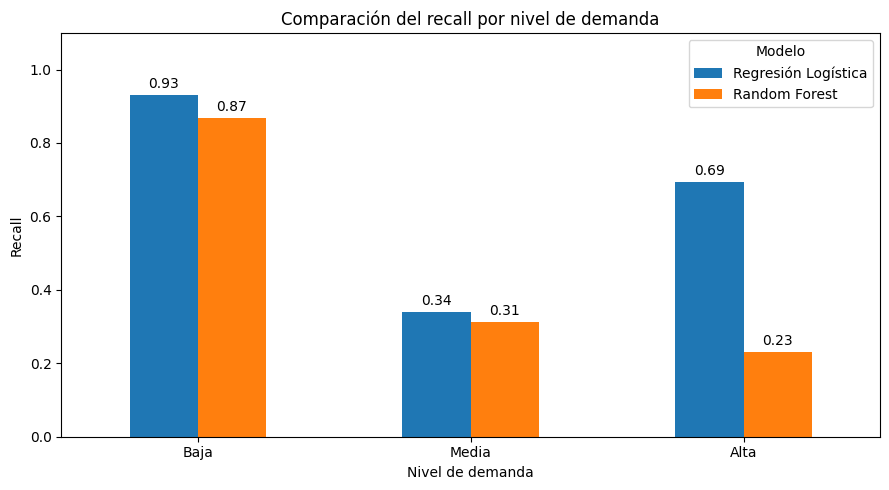

In [19]:
# Categorías de demanda
orden_niveles = ["Baja", "Media", "Alta"]

# Calcular recall por categoría para cada modelo
recall_logistica = recall_score(
    y_test,
    y_pred_logistica,
    labels=orden_niveles,
    average=None,
    zero_division=0
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    labels=orden_niveles,
    average=None,
    zero_division=0
)

# Crear DataFrame para comparar los resultados
df_recall = pd.DataFrame({
    "Nivel de demanda": orden_niveles,
    "Regresión Logística": recall_logistica,
    "Random Forest": recall_rf
})

# Generar gráfico de barras
ax = df_recall.set_index("Nivel de demanda").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Comparación del recall por nivel de demanda")
ax.set_xlabel("Nivel de demanda")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.1)

# Mostrar valores sobre las barras
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", padding=3)

plt.legend(title="Modelo")
plt.tight_layout()
plt.show()

**Interpretación del gráfico**

El gráfico permite observar que ambos modelos presentan un mejor desempeño en la identificación de la demanda Baja y mayores dificultades para clasificar la demanda Media.

En la categoría Alta se observa una diferencia importante: la Regresión Logística identifica aproximadamente el 69 % de los registros reales de demanda elevada, mientras que Random Forest identifica solamente el 23 %.

Estos resultados refuerzan la elección preliminar de la Regresión Logística como el modelo con mejor desempeño para los objetivos de la investigación, considerando las configuraciones evaluadas.

**Interpretación general de los resultados**

Los resultados obtenidos muestran que el modelo de **Regresión Logística presentó un mejor desempeño general** que Random Forest sobre el conjunto de prueba correspondiente al año 2021.

La Regresión Logística alcanzó una exactitud del **67,45 %** y un F1-score macro de **0,6277**, mientras que Random Forest obtuvo una exactitud del **56,84 %** y un F1-score macro de **0,4631**.

Al analizar los resultados por categoría, se observa que ambos modelos lograron identificar con mayor facilidad los registros de demanda Baja. En cambio, la categoría Media presentó mayores dificultades de clasificación, con valores de recall de 0,34 para Regresión Logística y 0,31 para Random Forest.

Una de las diferencias más relevantes se encuentra en la categoría **Alta**, donde la Regresión Logística alcanzó un recall de **0,69**, frente al **0,23** obtenido por Random Forest. Este resultado es especialmente importante para nuestra investigación, ya que buscamos identificar niveles elevados de demanda de pasajeros que podrían estar asociados con situaciones de congestión en la red de subtes.

La comparación permite observar que, con las configuraciones iniciales utilizadas, la Regresión Logística presenta una mejor capacidad predictiva sobre los registros de 2021. Sin embargo, los resultados también evidencian limitaciones, particularmente en la identificación de la demanda Media.

Estas diferencias deben interpretarse considerando que los patrones de movilidad pudieron haber cambiado durante el período analizado y que la distribución de los niveles de demanda en 2021 es diferente de la observada en los datos de entrenamiento.

En conclusión, **la Regresión Logística se presenta como el modelo más prometedor entre los dos evaluados hasta el momento**. No obstante, será necesario complementar el análisis mediante matrices de confusión para comprender mejor los errores de clasificación y evaluar posibles ajustes que permitan mejorar el desempeño de los modelos.

#### 7.4 Análisis mediante matrices de confusión

Para complementar la evaluación de los modelos, se utilizarán **matrices de confusión**, que permiten visualizar la distribución de las predicciones correctas e incorrectas para cada categoría de demanda.

Una matriz de confusión compara las categorías reales con las categorías predichas por el modelo:

- **Filas:** representan los niveles de demanda reales.
- **Columnas:** representan los niveles de demanda predichos.
- **Diagonal principal:** contiene los registros clasificados correctamente.
- **Valores fuera de la diagonal:** representan los errores de clasificación.

En esta investigación se construirán matrices de confusión para los modelos de Regresión Logística y Random Forest, considerando las categorías Baja, Media y Alta.

Este análisis permitirá identificar qué niveles de demanda presentan mayores dificultades de clasificación y determinar si los modelos tienden a confundir la demanda Alta con las categorías Media o Baja.

Dado que el objetivo del estudio incluye la identificación de situaciones de demanda elevada, se prestará especial atención a los registros de demanda Alta que no hayan sido reconocidos correctamente por los modelos.

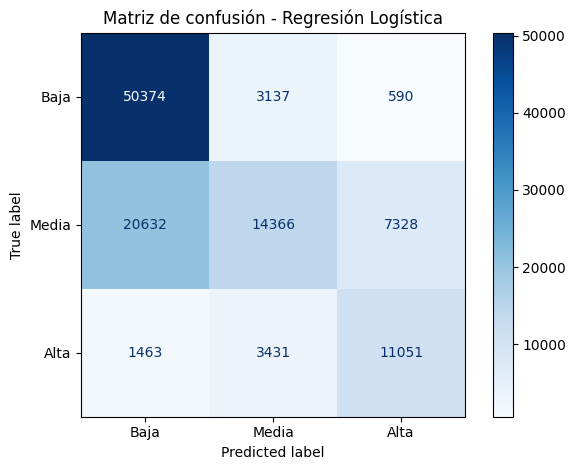

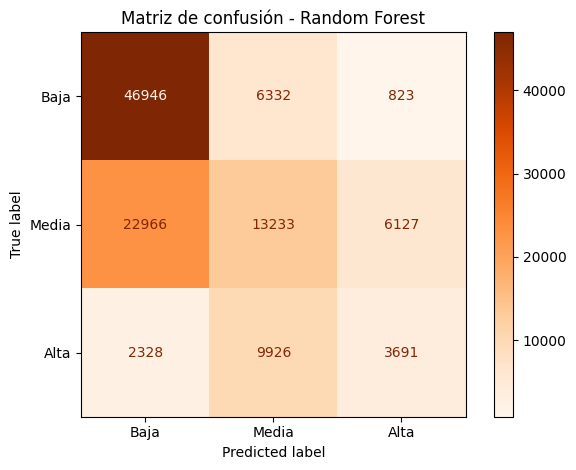

In [20]:
# Matrices de confusión de los modelos

orden_niveles = ["Baja", "Media", "Alta"]

# Calcular las matrices de confusión
matriz_logistica = confusion_matrix(
    y_test,
    y_pred_logistica,
    labels=orden_niveles
)

matriz_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=orden_niveles
)

# Visualizar la matriz de Regresión Logística
disp_logistica = ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=orden_niveles
)

disp_logistica.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Regresión Logística")
plt.tight_layout()
plt.show()

# Visualizar la matriz de Random Forest
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=orden_niveles
)

disp_rf.plot(cmap="Oranges", values_format="d")
plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

**Interpretación de las matrices de confusión**

El análisis de las matrices de confusión permite identificar los principales aciertos y errores de los modelos de Regresión Logística y Random Forest sobre los registros correspondientes a 2021.

En ambos modelos, la categoría **Baja** presenta la mayor cantidad de clasificaciones correctas. La Regresión Logística identificó correctamente 50.374 registros, mientras que Random Forest identificó 46.946.

La categoría **Media** presenta dificultades importantes en ambos algoritmos. En particular, se observa una tendencia a clasificar registros de demanda Media como Baja, con 20.632 casos en Regresión Logística y 22.966 en Random Forest.

Las diferencias más relevantes se observan en la categoría **Alta**. La Regresión Logística identificó correctamente 11.051 de los 15.945 registros reales, mientras que Random Forest reconoció solamente 3.691. En este último modelo, una parte considerable de los registros de demanda Alta fue clasificada incorrectamente como Media.

Estos resultados confirman que la Regresión Logística presenta una mayor capacidad para identificar niveles elevados de demanda con las configuraciones evaluadas, lo que resulta especialmente relevante para los objetivos de la investigación.

Sin embargo, ambos modelos muestran limitaciones, particularmente en la diferenciación de la demanda Media respecto de las categorías restantes.

En consecuencia, las matrices de confusión complementan las métricas obtenidas anteriormente y permiten comprender con mayor detalle los errores de clasificación, proporcionando información útil para evaluar posibles mejoras en los modelos.

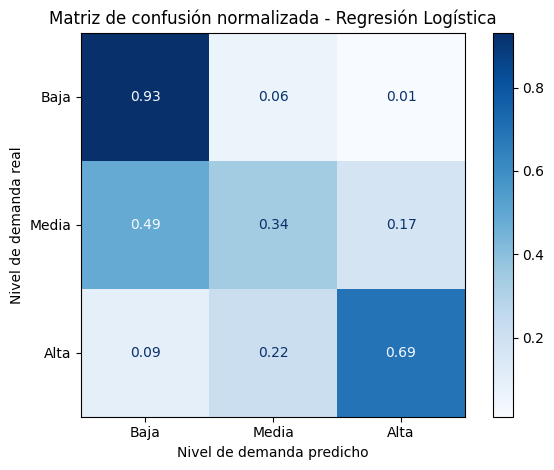

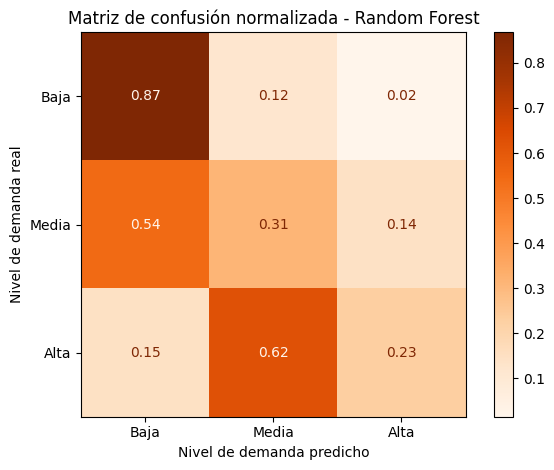

In [21]:
# Matrices de confusión normalizadas por categoría real

for nombre, predicciones, colores in [
    ("Regresión Logística", y_pred_logistica, "Blues"),
    ("Random Forest", y_pred_rf, "Oranges")
]:
    matriz_normalizada = confusion_matrix(
        y_test,
        predicciones,
        labels=orden_niveles,
        normalize="true"
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz_normalizada,
        display_labels=orden_niveles
    )

    disp.plot(cmap=colores, values_format=".2f")
    plt.title(f"Matriz de confusión normalizada - {nombre}")
    plt.xlabel("Nivel de demanda predicho")
    plt.ylabel("Nivel de demanda real")
    plt.tight_layout()
    plt.show()

**Interpretación de las matrices de confusión normalizadas**

Las matrices de confusión normalizadas permiten analizar la proporción de predicciones correctas e incorrectas para cada nivel de demanda, independientemente de la cantidad de registros que contiene cada categoría.

Los resultados muestran que ambos modelos presentan un mejor desempeño en la clasificación de la demanda Baja, con un 93 % de aciertos para Regresión Logística y un 87 % para Random Forest.

En la categoría Media se observan dificultades importantes, ya que ambos algoritmos tienden a clasificar una proporción considerable de estos registros como demanda Baja. Esta situación se presenta en aproximadamente el 49 % de los casos para Regresión Logística y el 54 % para Random Forest.

La principal diferencia aparece en la categoría Alta. Mientras que Regresión Logística identifica correctamente el 69 % de los registros, Random Forest reconoce solamente el 23 % y clasifica aproximadamente el 62 % como demanda Media.

En conjunto, estos resultados refuerzan lo observado en las métricas de clasificación y muestran que **Regresión Logística presenta un mejor desempeño para identificar niveles elevados de demanda**.

Sin embargo, ambos modelos evidencian dificultades para diferenciar correctamente la demanda Media, lo que representa una limitación que deberá considerarse al interpretar los resultados de la investigación.

###8. Ajuste de hiperparámetros y validación temporal de modelos

Una vez evaluados los modelos iniciales de Regresión Logística y Random Forest, se propone analizar posibles mejoras mediante el ajuste de hiperparámetros y la aplicación de una estrategia de validación temporal.

El objetivo de esta etapa es identificar configuraciones que permitan mejorar el desempeño predictivo de los algoritmos, especialmente en la clasificación de registros correspondientes a niveles elevados de demanda.

#### 8.1 Estrategia de validación temporal

Debido a que los datos utilizados en la investigación corresponden a una serie histórica de registros entre 2017 y 2021, se utilizará una división temporal que respete el orden cronológico de las observaciones.

Para el ajuste de los modelos se establecerán tres conjuntos:

*  **Entrenamiento (2017–2019):** utilizado para ajustar los parámetros internos de los modelos.

*  **Validación (2020):** utilizado para comparar distintas configuraciones de hiperparámetros y seleccionar las más adecuadas.

*  **Prueba (2021):** reservado para evaluar el desempeño de las configuraciones seleccionadas.

Esta estrategia permite evaluar los modelos sobre observaciones posteriores a las utilizadas durante el entrenamiento, evitando mezclar aleatoriamente registros de diferentes períodos.

La selección de hiperparámetros se realizará considerando principalmente el F1-score macro y el recall de la categoría Alta, debido a su importancia para los objetivos de la investigación.

Cabe señalar que el año 2020 presenta características particulares por los cambios en la movilidad asociados con la pandemia de COVID-19. Por lo tanto, los resultados de validación deberán interpretarse teniendo en cuenta esta circunstancia.

Asimismo, dado que los modelos iniciales ya fueron evaluados sobre los datos de 2021, se reconoce esta consulta previa como una limitación de la independencia del conjunto de prueba. Los ajustes posteriores se realizarán exclusivamente a partir del conjunto de validación de 2020.

#### 8.2 Preparación de los conjuntos de entrenamiento y validación

A partir de la estrategia de validación temporal definida en el apartado anterior, se prepararán los conjuntos de datos necesarios para el ajuste de hiperparámetros.

Para ello, se utilizará el DataFrame df_modelo, conservando los datos originales y creando nuevos conjuntos independientes para esta etapa del análisis.

Una vez realizada la separación, se verificará la cantidad de registros y los años incluidos en cada conjunto.

Posteriormente, se recalcularán los umbrales de clasificación de demanda a partir del conjunto de entrenamiento (2017–2019), utilizando los cuantiles 33,33 % y 66,67 %. Estos valores se aplicarán también al conjunto de validación para mantener un criterio de clasificación consistente y evitar utilizar información de 2020 durante la definición de los umbrales.

Finalmente, se prepararán las variables predictoras y la variable objetivo necesarias para entrenar y validar las nuevas configuraciones de los modelos.

In [22]:
# Crear conjuntos para la validación temporal

# Entrenamiento: 2017, 2018 y 2019
df_train_ajuste = df_modelo[
    df_modelo["anio"].between(2017, 2019)
].copy()

# Validación: 2020
df_val_ajuste = df_modelo[
    df_modelo["anio"] == 2020
].copy()

# Prueba: 2021
df_test_ajuste = df_modelo[
    df_modelo["anio"] == 2021
].copy()

# Verificar la cantidad de registros
print("Distribución temporal de los datos:")
print(f"Entrenamiento (2017-2019): {len(df_train_ajuste):,} registros")
print(f"Validación (2020): {len(df_val_ajuste):,} registros")
print(f"Prueba (2021): {len(df_test_ajuste):,} registros")

# Comprobar los años incluidos en cada conjunto
print("\nAños de entrenamiento:",
      sorted(df_train_ajuste["anio"].unique()))

print("Años de validación:",
      sorted(df_val_ajuste["anio"].unique()))

print("Años de prueba:",
      sorted(df_test_ajuste["anio"].unique()))


Distribución temporal de los datos:
Entrenamiento (2017-2019): 449,622 registros
Validación (2020): 91,625 registros
Prueba (2021): 112,372 registros

Años de entrenamiento: [np.int32(2017), np.int32(2018), np.int32(2019)]
Años de validación: [np.int32(2020)]
Años de prueba: [np.int32(2021)]


In [23]:
# Calcular los cuantiles utilizando solo entrenamiento (2017-2019)
cuantiles_ajuste = df_train_ajuste["pax_total"].quantile(
    [1/3, 2/3]
)

# Definir los nuevos umbrales de clasificación
umbral_bajo_ajuste = cuantiles_ajuste.loc[1/3]
umbral_alto_ajuste = cuantiles_ajuste.loc[2/3]

# Mostrar los resultados
print("Umbrales calculados con datos de 2017-2019:")
print(f"Demanda Baja: hasta {umbral_bajo_ajuste:.2f} pasajeros")
print(
    f"Demanda Media: más de {umbral_bajo_ajuste:.2f} "
    f"y hasta {umbral_alto_ajuste:.2f} pasajeros"
)
print(f"Demanda Alta: más de {umbral_alto_ajuste:.2f} pasajeros")

# Comparar con los umbrales originales (2017-2020)
print("\nComparación con los umbrales del Punto 4:")
print(f"Umbral bajo original: {umbral_bajo:.2f}")
print(f"Umbral bajo nuevo: {umbral_bajo_ajuste:.2f}")
print(f"Umbral alto original: {umbral_alto:.2f}")
print(f"Umbral alto nuevo: {umbral_alto_ajuste:.2f}")

Umbrales calculados con datos de 2017-2019:
Demanda Baja: hasta 508.00 pasajeros
Demanda Media: más de 508.00 y hasta 2156.00 pasajeros
Demanda Alta: más de 2156.00 pasajeros

Comparación con los umbrales del Punto 4:
Umbral bajo original: 354.00
Umbral bajo nuevo: 508.00
Umbral alto original: 1825.00
Umbral alto nuevo: 2156.00


In [24]:
# Clasificar la demanda con los nuevos umbrales (2017-2019)
def clasificar_demanda_ajuste(pasajeros):
    """
    Clasifica la demanda en Baja, Media o Alta utilizando
    los umbrales calculados con datos de 2017-2019.

    Parámetros:
        pasajeros: cantidad total de pasajeros del registro.

    Retorna:
        str: nivel de demanda correspondiente.
    """
    if pasajeros <= umbral_bajo_ajuste:
        return "Baja"
    elif pasajeros <= umbral_alto_ajuste:
        return "Media"
    else:
        return "Alta"


# Aplicar el mismo criterio a cada conjunto temporal
for conjunto in [df_train_ajuste, df_val_ajuste, df_test_ajuste]:
    conjunto["nivel_demanda"] = conjunto["pax_total"].apply(
        clasificar_demanda_ajuste
    )

# Verificar la distribución de categorías
orden_niveles = ["Baja", "Media", "Alta"]

for nombre, conjunto in [
    ("Entrenamiento (2017-2019)", df_train_ajuste),
    ("Validación (2020)", df_val_ajuste),
    ("Prueba (2021)", df_test_ajuste)
]:
    print(f"\n{nombre}")
    print(
        conjunto["nivel_demanda"]
        .value_counts()
        .reindex(orden_niveles, fill_value=0)
    )


Entrenamiento (2017-2019)
nivel_demanda
Baja     149984
Media    149790
Alta     149848
Name: count, dtype: int64

Validación (2020)
nivel_demanda
Baja     60854
Media    21205
Alta      9566
Name: count, dtype: int64

Prueba (2021)
nivel_demanda
Baja     63073
Media    37314
Alta     11985
Name: count, dtype: int64


In [25]:
# Preparar variables predictoras y objetivo para el ajuste

# Entrenamiento (2017-2019)
X_train_ajuste = df_train_ajuste[variables_predictoras].copy()
y_train_ajuste = df_train_ajuste["nivel_demanda"].copy()

# Validación (2020)
X_val_ajuste = df_val_ajuste[variables_predictoras].copy()
y_val_ajuste = df_val_ajuste["nivel_demanda"].copy()

# Prueba (2021): se mantiene reservado
X_test_ajuste = df_test_ajuste[variables_predictoras].copy()
y_test_ajuste = df_test_ajuste["nivel_demanda"].copy()

# Verificar dimensiones de los conjuntos
print("Dimensiones de los conjuntos:")
print("X_train_ajuste:", X_train_ajuste.shape)
print("y_train_ajuste:", y_train_ajuste.shape)

print("\nX_val_ajuste:", X_val_ajuste.shape)
print("y_val_ajuste:", y_val_ajuste.shape)

print("\nX_test_ajuste:", X_test_ajuste.shape)
print("y_test_ajuste:", y_test_ajuste.shape)

Dimensiones de los conjuntos:
X_train_ajuste: (449622, 6)
y_train_ajuste: (449622,)

X_val_ajuste: (91625, 6)
y_val_ajuste: (91625,)

X_test_ajuste: (112372, 6)
y_test_ajuste: (112372,)


#### 8.3 Ajuste de hiperparámetros de Regresión Logística

En esta etapa se evaluarán diferentes configuraciones del modelo de Regresión Logística con el objetivo de identificar aquella que presente un mejor desempeño sobre el conjunto de validación correspondiente al año 2020.

El ajuste se realizará modificando el hiperparámetro C, que controla la intensidad de la regularización aplicada al modelo. Los valores pequeños de C implican una regularización más fuerte, mientras que los valores grandes permiten una regularización más débil.

Para este análisis se seleccionaron tres valores:

*  **C = 0.1:** representa una regularización más fuerte, que limita en mayor medida la magnitud de los coeficientes del modelo.

*  **C = 1.0:** corresponde al valor predeterminado de scikit-learn y se utiliza como referencia para la comparación.

*  **C = 10.0:** representa una regularización más débil, que permite mayor flexibilidad en los coeficientes del modelo.

La selección de estos valores permite comparar configuraciones con diferentes intensidades de regularización y analizar su influencia sobre el desempeño predictivo.

Para comparar las configuraciones se utilizará la métrica F1-score macro, que calcula el promedio del F1-score de las tres categorías de demanda (Baja, Media y Alta), otorgándoles la misma importancia independientemente de la cantidad de registros.

Cada configuración será entrenada exclusivamente con los datos de 2017–2019 y evaluada con los datos de 2020. El conjunto de prueba de 2021 permanecerá reservado para la evaluación final.

La configuración seleccionada será aquella que obtenga el mayor F1-score macro en validación.

In [26]:
# Configuraciones de regularización para Regresión Logística
valores_c = [0.1, 1.0, 10.0]

print("Configuraciones de Regresión Logística a evaluar:")

for valor_c in valores_c:
    print(f"C = {valor_c}")

Configuraciones de Regresión Logística a evaluar:
C = 0.1
C = 1.0
C = 10.0


In [27]:
# Almacenar los resultados de cada configuración
resultados_logistica = []

# Entrenar y evaluar cada valor de C
for valor_c in valores_c:

    # Crear un pipeline independiente para cada configuración
    pipeline = Pipeline(
        steps=[
            ("preprocesamiento", clone(preprocesador)),
            ("clasificador", LogisticRegression(
                C=valor_c,
                max_iter=1000,
                random_state=42
            ))
        ]
    )

    # Entrenar con los datos de 2017-2019
    pipeline.fit(X_train_ajuste, y_train_ajuste)

    # Predecir sobre los datos de validación de 2020
    y_pred_val = pipeline.predict(X_val_ajuste)

    # Calcular las métricas de evaluación
    accuracy = accuracy_score(y_val_ajuste, y_pred_val)
    f1_macro = f1_score(
        y_val_ajuste,
        y_pred_val,
        average="macro"
    )

    # Guardar los resultados
    resultados_logistica.append({
        "C": valor_c,
        "Accuracy": accuracy,
        "F1-score macro": f1_macro
    })

    print(
        f"C = {valor_c} | "
        f"Accuracy = {accuracy:.4f} | "
        f"F1-score macro = {f1_macro:.4f}"
    )

C = 0.1 | Accuracy = 0.4275 | F1-score macro = 0.4036
C = 1.0 | Accuracy = 0.4275 | F1-score macro = 0.4035
C = 10.0 | Accuracy = 0.4273 | F1-score macro = 0.4034


**Resultados del ajuste de hiperparámetros**

Se evaluaron tres configuraciones de Regresión Logística, utilizando los valores `C = 0.1`, `C = 1.0` y `C = 10.0`.

Los resultados obtenidos sobre el conjunto de validación correspondiente a 2020 fueron los siguientes:

| C | Accuracy | F1-score macro |
|---|---|---|
| **0.1** | **0.4275** | **0.4036** |
| 1.0 | 0.4275 | 0.4035 |
| 10.0 | 0.4273 | 0.4034 |

La configuración `C = 0.1` presentó el mayor F1-score macro, aunque las diferencias entre los valores evaluados fueron mínimas. Esto indica que, dentro del rango analizado, la intensidad de regularización tuvo una influencia limitada sobre el desempeño del modelo.

En consecuencia, se seleccionó `C = 0.1` como la configuración más adecuada entre las alternativas evaluadas.

El desempeño obtenido también debe interpretarse considerando las diferencias en la distribución de los niveles de demanda entre el período de entrenamiento (2017–2019) y el conjunto de validación (2020).

In [28]:
# Crear una tabla con los resultados del ajuste
df_resultados_logistica = pd.DataFrame(resultados_logistica)

# Ordenar las configuraciones según el F1-score macro
df_resultados_logistica = df_resultados_logistica.sort_values(
    by="F1-score macro",
    ascending=False
).reset_index(drop=True)

# Identificar la configuración con mejor desempeño
mejor_c = df_resultados_logistica.loc[0, "C"]

print("Comparación de configuraciones:")
display(df_resultados_logistica)

print(f"\nMejor valor de C: {mejor_c}")

Comparación de configuraciones:


,C,Accuracy,F1-score macro
0,0.1,0.427547,0.403579
1,1.0,0.427503,0.403526
2,10.0,0.427263,0.403363



Mejor valor de C: 0.1


#### 8.4 Ajuste de hiperparámetros de Random Forest

En esta etapa se evaluarán diferentes configuraciones del modelo Random Forest con el objetivo de identificar aquella que presente un mejor desempeño sobre el conjunto de validación correspondiente a 2020.

Para el ajuste se seleccionaron dos hiperparámetros:

- **`n_estimators`:** determina la cantidad de árboles de decisión que conforman el modelo. Una mayor cantidad de árboles puede contribuir a estabilizar las predicciones, aunque también incrementa el tiempo de entrenamiento.
- **`max_depth`:** establece la profundidad máxima de cada árbol. Los valores más pequeños limitan la complejidad del modelo, mientras que los valores mayores permiten aprender relaciones más detalladas, con un posible incremento del riesgo de sobreajuste.

Se evaluarán las siguientes configuraciones:

- **`n_estimators = 50` y `100`:** permiten comparar dos cantidades de árboles y analizar su influencia sobre el desempeño y el costo computacional.
- **`max_depth = 10`, `15` y `20`:** permiten comparar árboles con diferentes niveles de complejidad.

La combinación de estos valores dará lugar a seis configuraciones de Random Forest.

Cada configuración será entrenada exclusivamente con los datos de 2017–2019 y evaluada sobre el conjunto de validación de 2020.

Al igual que en Regresión Logística, se utilizará el **F1-score macro** como métrica principal de comparación, otorgando la misma importancia a las categorías Baja, Media y Alta.

El conjunto de prueba de 2021 permanecerá reservado para la evaluación final, evitando utilizarlo durante la selección de hiperparámetros.

In [29]:
# Valores de hiperparámetros para Random Forest
valores_n_estimators = [50, 100]
valores_max_depth = [10, 15, 20]

# Mostrar las combinaciones que se evaluarán
print("Configuraciones de Random Forest a evaluar:")

for n_estimators in valores_n_estimators:
    for max_depth in valores_max_depth:
        print(
            f"n_estimators = {n_estimators} | "
            f"max_depth = {max_depth}"
        )

Configuraciones de Random Forest a evaluar:
n_estimators = 50 | max_depth = 10
n_estimators = 50 | max_depth = 15
n_estimators = 50 | max_depth = 20
n_estimators = 100 | max_depth = 10
n_estimators = 100 | max_depth = 15
n_estimators = 100 | max_depth = 20


In [30]:
# Almacenar los resultados de cada configuración
resultados_rf = []

# Evaluar las seis combinaciones de hiperparámetros
for n_estimators in valores_n_estimators:
    for max_depth in valores_max_depth:

        # Crear un pipeline independiente
        pipeline = Pipeline(
            steps=[
                ("preprocesamiento", clone(preprocesador)),
                ("clasificador", RandomForestClassifier(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    random_state=42,
                    n_jobs=-1
                ))
            ]
        )

        # Entrenar con los datos de 2017-2019
        pipeline.fit(X_train_ajuste, y_train_ajuste)

        # Predecir sobre los datos de validación de 2020
        y_pred_val = pipeline.predict(X_val_ajuste)

        # Calcular las métricas de evaluación
        accuracy = accuracy_score(y_val_ajuste, y_pred_val)
        f1_macro = f1_score(
            y_val_ajuste,
            y_pred_val,
            average="macro"
        )

        # Guardar los resultados
        resultados_rf.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "Accuracy": accuracy,
            "F1-score macro": f1_macro
        })

        print(
            f"n_estimators = {n_estimators} | "
            f"max_depth = {max_depth} | "
            f"Accuracy = {accuracy:.4f} | "
            f"F1-score macro = {f1_macro:.4f}"
        )

n_estimators = 50 | max_depth = 10 | Accuracy = 0.4222 | F1-score macro = 0.4016
n_estimators = 50 | max_depth = 15 | Accuracy = 0.4366 | F1-score macro = 0.4148
n_estimators = 50 | max_depth = 20 | Accuracy = 0.4455 | F1-score macro = 0.4225
n_estimators = 100 | max_depth = 10 | Accuracy = 0.4207 | F1-score macro = 0.4003
n_estimators = 100 | max_depth = 15 | Accuracy = 0.4359 | F1-score macro = 0.4147
n_estimators = 100 | max_depth = 20 | Accuracy = 0.4455 | F1-score macro = 0.4225


In [31]:
# Crear un DataFrame con los resultados de Random Forest
df_resultados_rf = pd.DataFrame(resultados_rf)

# Ordenar por F1-score macro y, en caso de empate,
# priorizar la menor cantidad de árboles
df_resultados_rf = df_resultados_rf.sort_values(
    by=["F1-score macro", "n_estimators"],
    ascending=[False, True]
).reset_index(drop=True)

# Identificar la mejor configuración
mejor_n_estimators = int(df_resultados_rf.loc[0, "n_estimators"])
mejor_max_depth = int(df_resultados_rf.loc[0, "max_depth"])

# Mostrar resultados con mayor precisión
print("Comparación de configuraciones de Random Forest:")
display(df_resultados_rf.round(6))

print("\nMejor configuración:")
print(f"n_estimators = {mejor_n_estimators}")
print(f"max_depth = {mejor_max_depth}")

Comparación de configuraciones de Random Forest:


,n_estimators,max_depth,Accuracy,F1-score macro
0,100,20,0.445533,0.422545
1,50,20,0.445490,0.422544
2,50,15,0.436573,0.414755
3,100,15,0.435853,0.414672
4,50,10,0.422188,0.401560
5,100,10,0.420715,0.400283



Mejor configuración:
n_estimators = 100
max_depth = 20


**Selección de la mejor configuración**

A partir de la comparación de las seis configuraciones evaluadas, se identificó que el modelo Random Forest con n_estimators = 100 y max_depth = 20 obtuvo el mayor F1-score macro sobre el conjunto de validación de 2020, alcanzando un valor de 0.422545 y una exactitud de 0.445533.

Sin embargo, la configuración de 50 árboles y profundidad máxima 20 presentó un desempeño prácticamente idéntico, con un F1-score macro de 0.422544. Esto indica que duplicar la cantidad de árboles no produjo una mejora relevante en términos predictivos.

Por lo tanto, se seleccionó la configuración de 100 árboles y profundidad 20 siguiendo el criterio de maximización del F1-score macro, aunque se reconoce que la alternativa de 50 árboles podría resultar conveniente si se priorizara una menor complejidad computacional.

#### 8.5 Comparación de configuraciones y selección del modelo

Una vez finalizado el ajuste de hiperparámetros de Regresión Logística y Random Forest, se compararán las configuraciones seleccionadas de ambos modelos.

La comparación se realizará utilizando los resultados obtenidos sobre el mismo conjunto de validación correspondiente a 2020, manteniendo las mismas variables predictoras, categorías de demanda y condiciones de evaluación.

Se considerarán las métricas Accuracy y F1-score macro, utilizando esta última como criterio principal de selección, debido a que permite evaluar el desempeño de las tres categorías de demanda con igual importancia.

Además de las métricas generales, se analizará el comportamiento de los modelos para cada nivel de demanda, especialmente su capacidad para identificar registros de demanda Alta.

A partir de estos resultados se seleccionará el modelo que presente el desempeño más adecuado para los objetivos de la investigación.

In [32]:
# Obtener los mejores resultados de cada modelo
mejor_logistica = df_resultados_logistica.iloc[0]
mejor_rf = df_resultados_rf.iloc[0]

# Construir una tabla comparativa
df_comparacion_modelos = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "Configuración": f"C = {mejor_c}",
        "Accuracy": mejor_logistica["Accuracy"],
        "F1-score macro": mejor_logistica["F1-score macro"]
    },
    {
        "Modelo": "Random Forest",
        "Configuración": (
            f"n_estimators = {mejor_n_estimators}, "
            f"max_depth = {mejor_max_depth}"
        ),
        "Accuracy": mejor_rf["Accuracy"],
        "F1-score macro": mejor_rf["F1-score macro"]
    }
])

# Ordenar los modelos según el F1-score macro
df_comparacion_modelos = df_comparacion_modelos.sort_values(
    by="F1-score macro",
    ascending=False
).reset_index(drop=True)

# Mostrar la comparación
print("Comparación de los mejores modelos:")
display(df_comparacion_modelos.round(6))

print(
    "\nModelo con mayor F1-score macro:",
    df_comparacion_modelos.loc[0, "Modelo"]
)

Comparación de los mejores modelos:


,Modelo,Configuración,Accuracy,F1-score macro
0,Random Forest,"n_estimators = 100, max_depth = 20",0.445533,0.422545
1,Regresión Logística,C = 0.1,0.427547,0.403579



Modelo con mayor F1-score macro: Random Forest


In [33]:
# Reconstruir los modelos con sus mejores hiperparámetros
modelo_logistica_ajuste = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", LogisticRegression(
            C=mejor_c,
            max_iter=1000,
            random_state=42
        ))
    ]
)

modelo_rf_ajuste = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", RandomForestClassifier(
            n_estimators=mejor_n_estimators,
            max_depth=mejor_max_depth,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entrenar exclusivamente con datos de 2017-2019
modelo_logistica_ajuste.fit(X_train_ajuste, y_train_ajuste)
modelo_rf_ajuste.fit(X_train_ajuste, y_train_ajuste)

# Predecir sobre validación (2020)
y_pred_logistica_val = modelo_logistica_ajuste.predict(X_val_ajuste)
y_pred_rf_val = modelo_rf_ajuste.predict(X_val_ajuste)

# Evaluar las tres categorías de demanda
print("REGRESIÓN LOGÍSTICA - VALIDACIÓN 2020")
print(classification_report(
    y_val_ajuste,
    y_pred_logistica_val,
    labels=["Baja", "Media", "Alta"],
    zero_division=0
))

print("\nRANDOM FOREST - VALIDACIÓN 2020")
print(classification_report(
    y_val_ajuste,
    y_pred_rf_val,
    labels=["Baja", "Media", "Alta"],
    zero_division=0
))

REGRESIÓN LOGÍSTICA - VALIDACIÓN 2020
              precision    recall  f1-score   support

        Baja       0.94      0.37      0.53     60854
       Media       0.27      0.41      0.32     21205
        Alta       0.23      0.85      0.36      9566

    accuracy                           0.43     91625
   macro avg       0.48      0.54      0.40     91625
weighted avg       0.71      0.43      0.46     91625


RANDOM FOREST - VALIDACIÓN 2020
              precision    recall  f1-score   support

        Baja       0.97      0.38      0.55     60854
       Media       0.29      0.43      0.34     21205
        Alta       0.24      0.91      0.38      9566

    accuracy                           0.45     91625
   macro avg       0.50      0.57      0.42     91625
weighted avg       0.74      0.45      0.48     91625



**Análisis del desempeño por nivel de demanda**

La evaluación de las mejores configuraciones sobre el conjunto de validación de 2020 permitió identificar diferencias en el desempeño de los modelos para las categorías Baja, Media y Alta.

Random Forest presentó resultados superiores a Regresión Logística en las tres categorías, considerando las métricas precision, recall y F1-score.

En particular, para la categoría de demanda Alta, Random Forest alcanzó un recall de 0.91, frente a 0.85 de Regresión Logística. Esto indica que logró identificar una mayor proporción de los registros que realmente pertenecían a ese nivel de demanda.

Sin embargo, la precision obtenida para demanda Alta fue de 0.24, lo que evidencia una cantidad considerable de registros clasificados incorrectamente como Alta. Por lo tanto, el buen desempeño en recall debe interpretarse junto con esta limitación.

La categoría Media presentó dificultades para ambos modelos, con valores de F1-score de 0.32 para Regresión Logística y 0.34 para Random Forest.

En cuanto a la demanda Baja, ambos modelos alcanzaron valores elevados de precision, aunque sus valores de recall fueron relativamente bajos.

En conjunto, los resultados muestran que Random Forest obtuvo un mejor desempeño general y una mayor capacidad para identificar registros de demanda Alta. No obstante, las limitaciones observadas en precision y en la clasificación de demanda Media deben considerarse al interpretar los resultados del modelo.

Estas diferencias también deben analizarse teniendo en cuenta el cambio en la distribución de la demanda entre el período de entrenamiento (2017–2019) y el año de validación (2020).

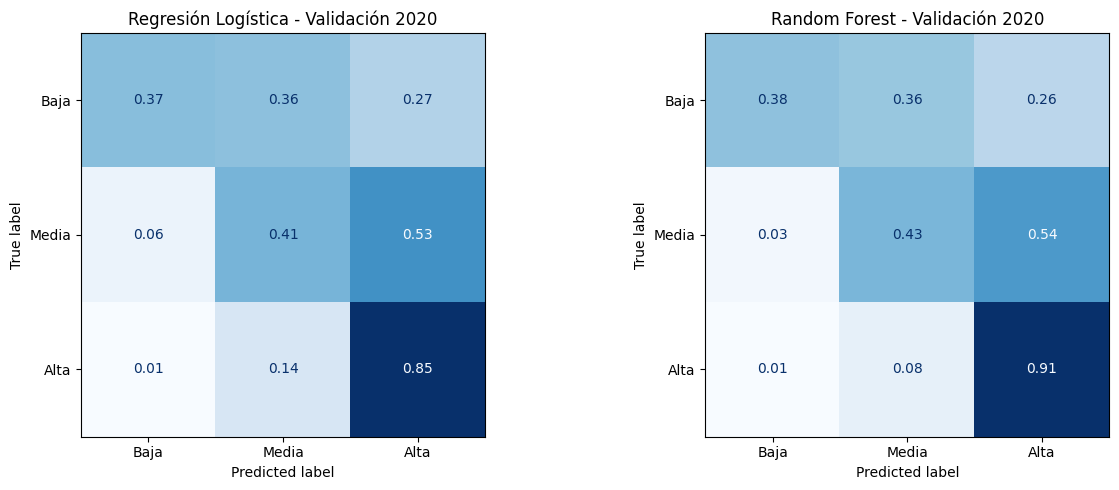

In [45]:
# Definir el orden de las categorías
orden_niveles = ["Baja", "Media", "Alta"]

# Crear las matrices de confusión normalizadas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val_ajuste,
    y_pred_logistica_val,
    labels=orden_niveles,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Regresión Logística - Validación 2020")

ConfusionMatrixDisplay.from_predictions(
    y_val_ajuste,
    y_pred_rf_val,
    labels=orden_niveles,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Random Forest - Validación 2020")

plt.tight_layout()
plt.show()

**Interpretación de las matrices de confusión y selección del modelo**

El análisis de las matrices de confusión normalizadas permitió profundizar en el comportamiento de las mejores configuraciones de Regresión Logística y Random Forest sobre el conjunto de validación correspondiente a 2020.

En la categoría de demanda Alta, Random Forest logró identificar correctamente el 91 % de los registros, superando el 85 % obtenido por Regresión Logística. Este resultado representa una ventaja para el objetivo de identificar situaciones de elevada demanda de pasajeros.

Sin embargo, ambos modelos presentaron dificultades para diferenciar las categorías Baja y Media de la categoría Alta. En particular, Random Forest clasificó incorrectamente como Alta al 54 % de los registros reales de demanda Media y al 26 % de los registros de demanda Baja.

Estas confusiones explican, en parte, la baja precision obtenida para la categoría Alta, a pesar de sus elevados valores de recall.

En términos generales, Random Forest obtuvo mejores resultados que Regresión Logística, tanto en F1-score macro (0.422545 frente a 0.403579) como en Accuracy (0.445533 frente a 0.427547).

Por este motivo, se seleccionó **Random Forest con 100 árboles y profundidad máxima 20** como el modelo con mejor desempeño entre las configuraciones evaluadas.

No obstante, los resultados evidencian limitaciones en la capacidad de clasificación, especialmente para distinguir los niveles intermedios y bajos de demanda. Estas limitaciones deben interpretarse considerando las diferencias en los patrones de movilidad entre el período de entrenamiento (2017–2019) y el año de validación (2020).

En consecuencia, la selección de Random Forest se considera una decisión basada en su desempeño comparativo, pero no implica que el modelo haya alcanzado un nivel de precisión suficiente para su aplicación operativa sin evaluaciones adicionales.

#### 8.6 Evaluación final y análisis de sensibilidad

Una vez seleccionado Random Forest como el modelo con mejor desempeño durante la validación temporal, se realizará una evaluación final utilizando los registros correspondientes al año 2021.

Para esta etapa, el modelo será reentrenado con los datos de 2017–2020, incorporando el período utilizado previamente para la validación. Se mantendrán los hiperparámetros seleccionados (`n_estimators = 100` y `max_depth = 20`), sin realizar nuevos ajustes a partir de los resultados de prueba.

La variable objetivo conservará los umbrales de clasificación calculados con los datos de 2017–2019: demanda Baja hasta 508 pasajeros, demanda Media entre 508 y 2.156 pasajeros, y demanda Alta por encima de 2.156 pasajeros.

El desempeño final se evaluará mediante Accuracy, F1-score macro, precision, recall y matrices de confusión, prestando especial atención a la identificación de registros de demanda Alta.

Posteriormente, se realizará un análisis de sensibilidad para examinar la estabilidad de los resultados frente a las diferencias temporales en la distribución de la demanda.

Los resultados deberán interpretarse considerando las particularidades del período 2020–2021 y las limitaciones de utilizar el volumen de pasajeros como indicador indirecto de congestión.

Asimismo, dado que el año 2021 ya fue utilizado en una evaluación exploratoria anterior, esta etapa se considerará una evaluación temporal posterior al ajuste, aunque no una prueba completamente independiente de todas las decisiones realizadas durante el estudio.

In [46]:
# Preparar los datos para el entrenamiento final (2017-2020)
df_train_final = pd.concat(
    [df_train_ajuste, df_val_ajuste],
    ignore_index=True
)

# Seleccionar las variables predictoras y la variable objetivo
X_train_final = df_train_final[variables_predictoras].copy()
y_train_final = df_train_final["nivel_demanda"].copy()

# Mantener 2021 como conjunto de prueba
X_test_final = X_test_ajuste.copy()
y_test_final = y_test_ajuste.copy()

# Verificar las dimensiones de los conjuntos
print("Entrenamiento final (2017-2020):")
print("X_train_final:", X_train_final.shape)
print("y_train_final:", y_train_final.shape)

print("\nPrueba final (2021):")
print("X_test_final:", X_test_final.shape)
print("y_test_final:", y_test_final.shape)

# Comprobar los años incluidos
print(
    "\nAños de entrenamiento:",
    sorted(df_train_final["anio"].unique())
)
print(
    "Años de prueba:",
    sorted(df_test_ajuste["anio"].unique())
)

Entrenamiento final (2017-2020):
X_train_final: (541247, 6)
y_train_final: (541247,)

Prueba final (2021):
X_test_final: (112372, 6)
y_test_final: (112372,)

Años de entrenamiento: [np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020)]
Años de prueba: [np.int32(2021)]


In [47]:
# Construir el modelo final con los hiperparámetros seleccionados
modelo_rf_final = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", RandomForestClassifier(
            n_estimators=mejor_n_estimators,
            max_depth=mejor_max_depth,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entrenar el modelo con los datos de 2017-2020
modelo_rf_final.fit(X_train_final, y_train_final)

print("Entrenamiento finalizado correctamente.")
print(f"Cantidad de árboles: {mejor_n_estimators}")
print(f"Profundidad máxima: {mejor_max_depth}")
print(f"Registros utilizados: {len(X_train_final):,}")

Entrenamiento finalizado correctamente.
Cantidad de árboles: 100
Profundidad máxima: 20
Registros utilizados: 541,247


**Evaluación del desempeño final**

Una vez entrenado el modelo Random Forest con los datos de 2017–2020, se generarán predicciones sobre el conjunto de prueba correspondiente a 2021.

Para evaluar su desempeño se utilizarán las siguientes métricas:

*  **Accuracy:** proporción total de predicciones correctas respecto del conjunto evaluado.

*  **F1-score macro:** promedio del F1-score de las tres categorías de demanda, otorgando la misma importancia a cada una.

*  **Precision:** proporción de predicciones de una categoría que realmente corresponden a ella.

*  **Recall:** proporción de registros reales de una categoría que el modelo logra identificar correctamente.

Estas métricas permitirán analizar tanto el desempeño general del modelo como su capacidad para distinguir los niveles de demanda Baja, Media y Alta.

Se prestará especial atención a la categoría Alta, debido a su relevancia para los objetivos de la investigación.

In [48]:
# Generar predicciones sobre el conjunto de prueba (2021)
y_pred_rf_final = modelo_rf_final.predict(X_test_final)

# Calcular las métricas generales
accuracy_final = accuracy_score(
    y_test_final,
    y_pred_rf_final
)

f1_macro_final = f1_score(
    y_test_final,
    y_pred_rf_final,
    average="macro"
)

# Mostrar los resultados generales
print("EVALUACIÓN FINAL - RANDOM FOREST (2021)")
print(f"Accuracy: {accuracy_final:.4f}")
print(f"F1-score macro: {f1_macro_final:.4f}")

# Mostrar las métricas por categoría de demanda
print("\nReporte de clasificación:")
print(
    classification_report(
        y_test_final,
        y_pred_rf_final,
        labels=["Baja", "Media", "Alta"],
        zero_division=0
    )
)

EVALUACIÓN FINAL - RANDOM FOREST (2021)
Accuracy: 0.5825
F1-score macro: 0.3999

Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.66      0.90      0.76     63073
       Media       0.35      0.18      0.24     37314
        Alta       0.26      0.16      0.20     11985

    accuracy                           0.58    112372
   macro avg       0.42      0.41      0.40    112372
weighted avg       0.52      0.58      0.53    112372



**Interpretación de los resultados finales**

La evaluación del modelo Random Forest sobre los registros correspondientes a 2021 permitió obtener un Accuracy de 0.5825 y un F1-score macro de 0.3999.

En comparación con los resultados de validación de 2020, se observó un incremento en el Accuracy, acompañado de una disminución del F1-score macro. Esto indica que el aumento en la proporción general de predicciones correctas no estuvo acompañado por una mejora equilibrada en las tres categorías de demanda.

El modelo presentó un mejor desempeño para la categoría Baja, alcanzando un recall de 0.90 y un F1-score de 0.76.

Sin embargo, se observaron dificultades importantes para identificar las categorías Media y Alta, cuyos valores de recall fueron de 0.18 y 0.16, respectivamente.

En particular, la disminución del recall de demanda Alta respecto de la validación de 2020 evidencia una limitación relevante para los objetivos de la investigación, dado que esta categoría representa los registros de mayor volumen de pasajeros.

Las diferencias observadas pueden estar relacionadas con los cambios en la distribución temporal de la demanda y con la incorporación de 2020 al entrenamiento final, aunque los resultados disponibles no permiten determinar la contribución específica de cada factor.

Por lo tanto, si bien Random Forest fue el modelo seleccionado por su desempeño comparativo durante la validación, los resultados finales muestran que su capacidad de generalización presenta limitaciones, especialmente para identificar niveles de demanda Media y Alta.

**Análisis de la matriz de confusión final**

Para complementar las métricas de evaluación, se construirá una matriz de confusión normalizada utilizando las predicciones del modelo Random Forest sobre el conjunto de prueba de 2021.

Esta matriz permitirá identificar qué proporción de registros de cada nivel de demanda fue clasificada correctamente y hacia qué categorías se dirigieron las predicciones incorrectas.

La normalización por categoría real facilitará la comparación entre los niveles Baja, Media y Alta, independientemente de las diferencias en la cantidad de registros de cada clase.

Se prestará especial atención a los errores asociados con la demanda Alta, debido a su relevancia para el objetivo de la investigación.

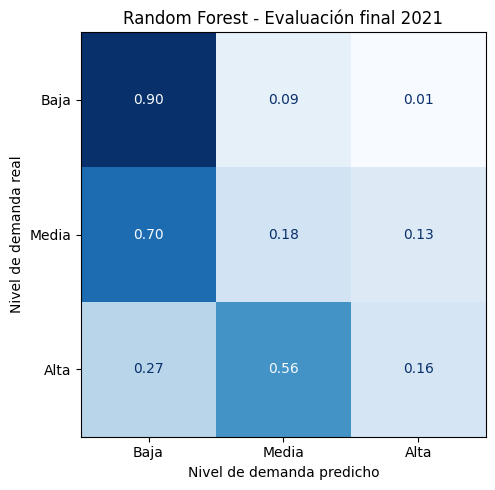

In [49]:
# Definir el orden de las categorías
orden_niveles = ["Baja", "Media", "Alta"]

# Generar la matriz de confusión normalizada para 2021
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_final,
    y_pred_rf_final,
    labels=orden_niveles,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax,
    colorbar=False
)

# Personalizar el gráfico
ax.set_title("Random Forest - Evaluación final 2021")
ax.set_xlabel("Nivel de demanda predicho")
ax.set_ylabel("Nivel de demanda real")

plt.tight_layout()
plt.show()

**Interpretación de la matriz de confusión final**

La matriz de confusión normalizada correspondiente a 2021 permitió identificar diferencias importantes en la capacidad del modelo Random Forest para clasificar los distintos niveles de demanda.

Los resultados obtenidos se resumen en la siguiente tabla:

| Demanda real | Predicha Baja | Predicha Media | Predicha Alta |
|---|---:|---:|---:|
| **Baja** | **90 %** | 9 % | 1 % |
| **Media** | 70 % | **18 %** | 13 % |
| **Alta** | 27 % | 56 % | **16 %** |

*Nota: los porcentajes son aproximados y pueden presentar pequeñas diferencias debido al redondeo.*

**Análisis por nivel de demanda**

- **Demanda Baja:** el modelo identificó correctamente aproximadamente el 90 % de los registros reales, siendo la categoría con mejor desempeño.

- **Demanda Media:** solamente el 18 % de los registros fue clasificado correctamente, mientras que aproximadamente el 70 % se identificó incorrectamente como demanda Baja. Esto evidencia una dificultad importante para reconocer los niveles intermedios.

- **Demanda Alta:** únicamente el 16 % de los registros fue identificado correctamente. Aproximadamente el 56 % se clasificó como demanda Media y el 27 % como demanda Baja. Este resultado es especialmente relevante, ya que la identificación de niveles elevados de demanda constituye uno de los objetivos centrales de la investigación.

**Interpretación general**

Los resultados evidencian una tendencia del modelo a subestimar los niveles de demanda durante 2021, especialmente en las categorías Media y Alta.

En comparación con la validación de 2020, donde Random Forest había alcanzado un recall de 0.91 para demanda Alta, la evaluación final muestra una disminución considerable de su capacidad para identificar esta categoría.

Si bien Random Forest fue seleccionado por presentar el mejor desempeño durante la validación, los resultados finales indican limitaciones en su capacidad de generalización temporal.

Por lo tanto, las predicciones deben interpretarse con precaución, especialmente cuando se utilizan para identificar niveles elevados de demanda como indicador indirecto de posibles situaciones de congestión.

#### 8.7 Análisis de sensibilidad temporal

Con el objetivo de examinar la estabilidad del desempeño predictivo, se compararán los resultados obtenidos durante la validación de 2020 y la evaluación final de 2021.

El análisis se centrará en tres métricas:

- **Accuracy:** permitirá comparar la proporción general de predicciones correctas entre ambos períodos.
- **F1-score macro:** permitirá observar si el desempeño global se mantiene equilibrado entre los tres niveles de demanda.
- **Recall de demanda Alta:** permitirá analizar las variaciones en la capacidad del modelo para identificar registros con elevados volúmenes de pasajeros.

Esta comparación permitirá reconocer diferencias en el comportamiento predictivo entre períodos.

Sin embargo, debe considerarse que los modelos evaluados fueron entrenados con diferentes ventanas temporales: el modelo validado en 2020 utilizó datos de 2017–2019, mientras que el modelo evaluado en 2021 incorporó también los registros de 2020.

Por lo tanto, las variaciones observadas no podrán atribuirse exclusivamente al año de evaluación, sino que se interpretarán como diferencias entre dos evaluaciones temporales del procedimiento de modelado.

In [50]:
# Calcular las métricas de validación de 2020
accuracy_2020 = accuracy_score(
    y_val_ajuste, y_pred_rf_val
)

f1_macro_2020 = f1_score(
    y_val_ajuste,
    y_pred_rf_val,
    average="macro"
)

recall_alta_2020 = recall_score(
    y_val_ajuste,
    y_pred_rf_val,
    labels=["Alta"],
    average="macro"
)

# Calcular el recall de demanda Alta para 2021
recall_alta_2021 = recall_score(
    y_test_final,
    y_pred_rf_final,
    labels=["Alta"],
    average="macro"
)

# Construir una tabla comparativa
df_sensibilidad_temporal = pd.DataFrame({
    "Período": ["Validación 2020", "Evaluación 2021"],
    "Accuracy": [accuracy_2020, accuracy_final],
    "F1-score macro": [f1_macro_2020, f1_macro_final],
    "Recall Alta": [recall_alta_2020, recall_alta_2021]
})

# Mostrar los resultados
print("Comparación del desempeño temporal:")
display(df_sensibilidad_temporal.round(4))

Comparación del desempeño temporal:


,Período,Accuracy,F1-score macro,Recall Alta
0,Validación 2020,0.4455,0.4225,0.9098
1,Evaluación 2021,0.5825,0.3999,0.1630


**Interpretación del análisis de sensibilidad temporal**

La comparación del desempeño de Random Forest entre la validación de 2020 y la evaluación final de 2021 permitió identificar diferencias importantes en las métricas predictivas.

| Métrica | Validación 2020 | Evaluación 2021 |
|---|---:|---:|
| Accuracy | 0.4455 | 0.5825 |
| F1-score macro | 0.4225 | 0.3999 |
| Recall de demanda Alta | 0.9098 | 0.1630 |

**Análisis de los resultados**

- **Accuracy:** aumentó de 0.4455 a 0.5825, lo que indica una mayor proporción general de predicciones correctas durante la evaluación de 2021.

- **F1-score macro:** disminuyó de 0.4225 a 0.3999, lo que evidencia que la mejora en Accuracy no estuvo acompañada por un mejor desempeño equilibrado entre las categorías.

- **Recall de demanda Alta:** presentó la variación más significativa, disminuyendo de 0.9098 a 0.1630. Esto representa una reducción aproximada de 74,68 puntos porcentuales en la capacidad de identificar correctamente los registros reales de demanda Alta.

**Interpretación general**

Los resultados muestran diferencias importantes en el desempeño predictivo entre las dos evaluaciones temporales, especialmente en la identificación de niveles elevados de demanda.

Durante 2020, Random Forest logró identificar una proporción elevada de los registros de demanda Alta, aunque con una precision reducida. En cambio, durante 2021, el modelo presentó una mayor capacidad para identificar la demanda Baja, pero dificultades considerables para reconocer los niveles Media y Alta.

Estas variaciones deben interpretarse considerando que el modelo validado en 2020 fue entrenado con registros de 2017–2019, mientras que el modelo evaluado en 2021 incorporó también los datos de 2020. Por lo tanto, no es posible atribuir las diferencias observadas exclusivamente al cambio de período.

En conjunto, los resultados evidencian limitaciones en la estabilidad temporal del procedimiento predictivo y destacan la necesidad de considerar los cambios en los patrones de demanda al desarrollar modelos destinados a identificar posibles situaciones de congestión.

Asimismo, los resultados sugieren que futuras mejoras podrían incluir estrategias de validación temporal adicionales, revisión de variables predictoras y evaluación de métodos que permitan mejorar la identificación de las categorías Media y Alta.

#### 8.8 Conclusiones del ajuste y la validación temporal

El proceso de ajuste de hiperparámetros y validación temporal permitió comparar el desempeño de Regresión Logística y Random Forest para la clasificación de los niveles de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires.

Para esta etapa se estableció una estrategia de separación temporal, utilizando los registros de 2017–2019 para entrenamiento, 2020 para validación y 2021 para evaluación final. Asimismo, se recalcularon los umbrales de clasificación a partir del período de entrenamiento, definiendo tres categorías: Baja, Media y Alta.

**Selección del modelo**

Durante la validación de 2020, Random Forest presentó un desempeño superior al de Regresión Logística, alcanzando un F1-score macro de 0.4225 frente a 0.4036.

A partir de estos resultados, se seleccionó Random Forest con 100 árboles y profundidad máxima de 20 como la configuración con mejor desempeño entre las alternativas evaluadas.

**Evaluación final**

Posteriormente, el modelo seleccionado fue reentrenado utilizando los registros de 2017–2020 y evaluado sobre 2021.

En esta evaluación se obtuvo un Accuracy de 0.5825 y un F1-score macro de 0.3999.

Aunque el modelo logró identificar correctamente una proporción elevada de los registros de demanda Baja, presentó dificultades importantes para clasificar los niveles Media y Alta.

En particular, el recall de demanda Alta alcanzó solamente 0.1630, lo que representa una limitación relevante para el objetivo de identificar situaciones de elevada demanda.

**Estabilidad temporal y limitaciones**

La comparación entre las evaluaciones de 2020 y 2021 mostró diferencias considerables en el comportamiento predictivo, especialmente en la identificación de demanda Alta.

Estas variaciones deben interpretarse teniendo en cuenta los cambios en la distribución de la demanda y las diferentes ventanas de entrenamiento utilizadas.

Además, el estudio presenta otras limitaciones metodológicas:

- La cantidad de pasajeros se utiliza como indicador indirecto de congestión, sin disponer de mediciones directas de ocupación o capacidad de los servicios.
- El período 2017–2021 incluye años afectados por cambios extraordinarios en los patrones de movilidad.
- Las variables predictoras disponibles no incorporan factores externos, como feriados, condiciones meteorológicas o modificaciones en la frecuencia del servicio.
- La evaluación de 2021 constituye una comprobación temporal posterior al ajuste, pero no una prueba completamente independiente de todas las decisiones del estudio, debido a su utilización exploratoria previa.

**Consideraciones finales**

Los resultados permitieron identificar a Random Forest como el modelo con mejor desempeño comparativo durante la validación. Sin embargo, la evaluación final evidenció limitaciones en su capacidad de generalización temporal, especialmente para reconocer niveles elevados de demanda.

En consecuencia, el modelo desarrollado debe considerarse una aproximación exploratoria al problema de clasificación de demanda y no una herramienta predictiva suficientemente validada para su utilización operativa.

Como posibles líneas de mejora, se propone incorporar nuevas variables explicativas, evaluar estrategias adicionales de validación temporal, revisar los criterios de clasificación y explorar alternativas de modelado que permitan mejorar la identificación de las categorías Media y Alta.

En conjunto, esta etapa permitió cumplir con el objetivo de desarrollar, comparar y evaluar modelos de clasificación, además de reconocer las principales dificultades asociadas con la predicción de la demanda de pasajeros en distintos períodos temporales.

### 9. Análisis complementario mediante K-Means

#### 9.1 Objetivo del análisis de agrupamiento

Como complemento de los modelos de clasificación supervisada desarrollados en los apartados anteriores, se propone aplicar el algoritmo K-Means para explorar patrones de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021.

K-Means es una técnica de aprendizaje no supervisado que permite agrupar observaciones en función de la similitud de sus características, sin utilizar una variable objetivo previamente definida.

A diferencia de Regresión Logística y Random Forest, que fueron entrenados para predecir los niveles de demanda Baja, Media y Alta, este análisis buscará identificar agrupaciones presentes en los datos y examinar sus características.

Para ello, se considerarán variables relacionadas con el volumen de pasajeros y las características temporales de los registros, evaluando su preparación y transformación antes de aplicar el algoritmo.

El objetivo será determinar si los grupos identificados presentan diferencias relevantes en los niveles de demanda y si permiten complementar el diagnóstico realizado mediante los modelos supervisados.

Los agrupamientos obtenidos no se interpretarán automáticamente como categorías de congestión, sino como patrones exploratorios cuya utilidad deberá analizarse a partir de las características de los registros que integran cada grupo.

#### 9.2 Selección y preparación de variables

Para aplicar K-Means se utilizará el conjunto de datos histórico procesado, correspondiente al período 2017–2021.

A diferencia de los modelos supervisados desarrollados anteriormente, el agrupamiento no utilizará la variable objetivo `nivel_demanda`, ya que el propósito es identificar patrones de similitud sin partir de categorías previamente definidas.

Se considerarán variables que permitan caracterizar los registros según el volumen de pasajeros y sus características temporales.

En particular, se propone utilizar:

- **`pax_total`:** cantidad total de pasajeros registrada, que permitirá identificar diferencias en los volúmenes de demanda.
- **`franja_horaria_num`:** franja horaria del registro, para explorar posibles patrones de demanda según el momento del día.
- **`dia_semana`:** día de la semana, para considerar diferencias entre días laborales y fines de semana.

Estas variables representan distintos aspectos del comportamiento de la demanda. Sin embargo, se tendrá en cuenta que las variables temporales poseen características particulares: sus valores numéricos representan categorías u ordenamientos temporales y no necesariamente distancias equivalentes entre observaciones.

Antes del entrenamiento, se revisarán sus tipos de datos, valores faltantes y distribuciones. Posteriormente, se evaluará la necesidad de aplicar transformaciones y escalado, debido a que K-Means utiliza distancias para construir los agrupamientos.

El análisis tendrá un carácter exploratorio y los clusters obtenidos serán interpretados a partir de las características de los registros que los integran.

In [51]:
# Seleccionar las variables para el análisis de agrupamiento
variables_kmeans = [
    "pax_total",
    "franja_horaria_num",
    "dia_semana"
]

# Crear un DataFrame independiente
df_kmeans = df_modelo[variables_kmeans].copy()

# Verificar dimensiones y tipos de datos
print("Dimensiones del dataset para K-Means:")
print(df_kmeans.shape)

print("\nTipos de datos:")
print(df_kmeans.dtypes)

# Verificar valores faltantes
print("\nValores faltantes por variable:")
print(df_kmeans.isnull().sum())

# Revisar estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df_kmeans.describe())

Dimensiones del dataset para K-Means:
(653619, 3)

Tipos de datos:
pax_total             float64
franja_horaria_num      int32
dia_semana              int32
dtype: object

Valores faltantes por variable:
pax_total             0
franja_horaria_num    0
dia_semana            0
dtype: int64

Estadísticas descriptivas:


,pax_total,franja_horaria_num,dia_semana
count,653619.000000,653619.000000,653619.000000
mean,1823.677125,3.110635,2.901201
std,3064.510711,1.368086,1.962620
min,0.000000,1.000000,0.000000
25%,153.000000,2.000000,1.000000
50%,756.000000,3.000000,3.000000
75%,2277.000000,4.000000,5.000000
max,63296.000000,5.000000,6.000000


**Transformación de variables para K-Means**

El análisis descriptivo confirmó que el conjunto de datos contiene 653.619 registros y tres variables numéricas, sin valores faltantes.

Se observó una diferencia considerable entre las escalas de las variables. En particular, pax_total presenta una elevada dispersión, con una mediana de 756 pasajeros y un valor máximo de 63.296.

Dado que K-Means utiliza distancias para determinar la similitud entre observaciones, se realizarán transformaciones para evitar que las diferencias de escala condicionen excesivamente los agrupamientos.

Se aplicará una transformación logarítmica al volumen de pasajeros, una representación cíclica del día de la semana y un escalado posterior de las características.

Estas decisiones buscan mejorar la representación de los datos para el análisis exploratorio, aunque los agrupamientos obtenidos dependerán de las variables y transformaciones seleccionadas.

In [52]:
# Crear una copia para transformar las variables
df_kmeans_transformado = df_kmeans.copy()

# Reducir la influencia de valores elevados de pasajeros
df_kmeans_transformado["pax_total_log"] = np.log1p(
    df_kmeans_transformado["pax_total"]
)

# Representar el día de la semana como una variable cíclica
df_kmeans_transformado["dia_semana_sin"] = np.sin(
    2 * np.pi * df_kmeans_transformado["dia_semana"] / 7
)

df_kmeans_transformado["dia_semana_cos"] = np.cos(
    2 * np.pi * df_kmeans_transformado["dia_semana"] / 7
)

# Seleccionar las características transformadas
columnas_kmeans = [
    "pax_total_log",
    "franja_horaria_num",
    "dia_semana_sin",
    "dia_semana_cos"
]

X_kmeans = df_kmeans_transformado[columnas_kmeans].copy()

print("Dimensiones de los datos transformados:")
print(X_kmeans.shape)

print("\nEstadísticas descriptivas:")
display(X_kmeans.describe().round(3))

print("\nPrimeros registros:")
display(X_kmeans.head())

Dimensiones de los datos transformados:
(653619, 4)

Estadísticas descriptivas:


,pax_total_log,franja_horaria_num,dia_semana_sin,dia_semana_cos
count,653619.000,653619.000,653619.000,653619.000
mean,6.209,3.111,0.035,-0.015
std,2.031,1.368,0.701,0.712
min,0.000,1.000,-0.975,-0.901
25%,5.037,2.000,-0.782,-0.901
50%,6.629,3.000,0.000,-0.223
75%,7.731,4.000,0.782,0.623
max,11.056,5.000,0.975,1.000



Primeros registros:


,pax_total_log,franja_horaria_num,dia_semana_sin,dia_semana_cos
0,6.284134,5,0.000000,1.000000
1,2.302585,1,0.781831,0.623490
2,7.561642,2,0.781831,0.623490
3,8.377011,3,0.781831,0.623490
4,7.451822,2,0.974928,-0.222521


**Resultados de la transformación de variables**

Las transformaciones se aplicaron correctamente sobre los 653.619 registros del conjunto de datos.

La transformación logarítmica redujo la amplitud de los valores de pasajeros, mientras que la representación cíclica del día de la semana permitió conservar su comportamiento periódico.

Como resultado, se obtuvo un conjunto de cuatro características numéricas que serán utilizadas en el análisis de agrupamiento.

No obstante, las variables transformadas todavía presentan diferencias de escala, por lo que se realizará una estandarización antes de aplicar K-Means.

**Escalado de variables**

Esta herramienta transforma cada característica para que tenga aproximadamente:
- Media igual a 0.
- Desviación estándar igual a 1.
Esto evita que una variable domine las distancias únicamente por tener una escala numérica mayor.

In [53]:
# Crear el escalador para las variables de K-Means
escalador_kmeans = StandardScaler()

# Ajustar el escalador y transformar las características
X_kmeans_escalado = escalador_kmeans.fit_transform(X_kmeans)

# Convertir el resultado a DataFrame para facilitar su revisión
df_kmeans_escalado = pd.DataFrame(
    X_kmeans_escalado,
    columns=columnas_kmeans,
    index=X_kmeans.index
)

# Verificar las dimensiones
print("Dimensiones de los datos escalados:")
print(df_kmeans_escalado.shape)

# Revisar estadísticas descriptivas
print("\nEstadísticas descriptivas después del escalado:")
display(df_kmeans_escalado.describe().round(3))

# Visualizar los primeros registros
print("\nPrimeros registros escalados:")
display(df_kmeans_escalado.head())

Dimensiones de los datos escalados:
(653619, 4)

Estadísticas descriptivas después del escalado:


,pax_total_log,franja_horaria_num,dia_semana_sin,dia_semana_cos
count,653619.000,653619.000,653619.000,653619.000
mean,-0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000
min,-3.056,-1.543,-1.441,-1.244
25%,-0.577,-0.812,-1.166,-1.244
50%,0.207,-0.081,-0.050,-0.292
75%,0.749,0.650,1.066,0.896
max,2.386,1.381,1.341,1.424



Primeros registros escalados:


,pax_total_log,franja_horaria_num,dia_semana_sin,dia_semana_cos
0,0.037073,1.381029,-0.050052,1.424407
1,-1.922890,-1.542766,1.065571,0.895854
2,0.665941,-0.811817,1.065571,0.895854
3,1.067316,-0.080868,1.065571,0.895854
4,0.611881,-0.811817,1.341107,-0.291794


**Resultados del escalado de variables**

Se aplicó `StandardScaler` sobre las cuatro características seleccionadas para el análisis de agrupamiento.

Los resultados muestran que todas las variables presentan una media aproximadamente igual a cero y una desviación estándar cercana a uno, manteniendo los 653.619 registros originales.

Este procedimiento permitió reducir las diferencias de escala entre las características, evitando que una variable tenga mayor influencia sobre las distancias únicamente por su magnitud numérica.

De esta manera, se obtuvo un conjunto de datos preparado para la aplicación de K-Means. Los agrupamientos resultantes deberán interpretarse considerando las transformaciones realizadas y las características seleccionadas.

#### 9.3 Determinación del número de clusters

Para determinar una cantidad adecuada de clusters, se evaluarán diferentes valores de `k` mediante criterios exploratorios.

Inicialmente, se utilizará el método del codo, que consiste en analizar la variación de la inercia del modelo a medida que aumenta el número de grupos.

La inercia representa la suma de las distancias cuadráticas entre las observaciones y los centroides de sus respectivos clusters. Su valor disminuye o se mantiene al aumentar `k`, por lo que se buscará identificar un punto a partir del cual la mejora resulte menos pronunciada.

Debido al tamaño del conjunto de datos, esta evaluación se realizará sobre una muestra aleatoria reproducible de los registros escalados, con el objetivo de reducir el costo computacional.

Posteriormente, se complementará el análisis con el coeficiente de silueta para evaluar la cohesión y separación de los agrupamientos.


##### 9.3.1 Método del codo

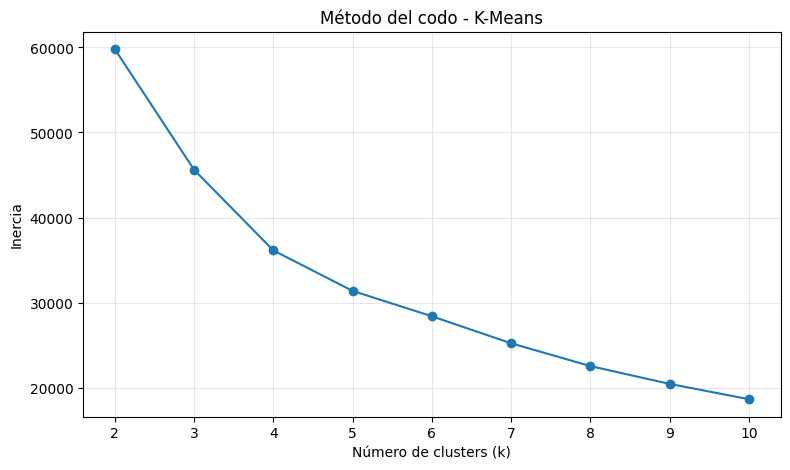

In [54]:
# Seleccionar una muestra reproducible para evaluar los clusters
X_kmeans_muestra = df_kmeans_escalado.sample(
    n=20000,
    random_state=42
)

# Definir los valores de k que se evaluarán
valores_k = range(2, 11)

# Almacenar la inercia de cada modelo
inercias = []

for k in valores_k:
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo_kmeans.fit(X_kmeans_muestra)
    inercias.append(modelo_kmeans.inertia_)

# Visualizar la evolución de la inercia
plt.figure(figsize=(9, 5))
plt.plot(list(valores_k), inercias, marker="o")

plt.title("Método del codo - K-Means")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

**Interpretación del método del codo**

El gráfico muestra una disminución progresiva de la inercia a medida que aumenta el número de clusters.

Las reducciones más pronunciadas se observan entre dos y cuatro clusters. A partir de cuatro o cinco grupos, la curva presenta una pendiente menos marcada, lo que indica que incorporar nuevos clusters produce mejoras progresivamente menores en la compactación de los agrupamientos.

No obstante, el gráfico no presenta un punto de inflexión completamente definido. Por este motivo, se consideran cuatro y cinco clusters como posibles alternativas, cuya conveniencia será evaluada mediante el coeficiente de silueta.

Este análisis permitirá complementar el método del codo antes de seleccionar la cantidad de grupos para el entrenamiento final.

##### 9.3.2 Evaluación mediante el coeficiente de silueta

Como complemento del método del codo, se utilizará el coeficiente de silueta para evaluar la calidad de los agrupamientos.

Esta métrica considera tanto la cohesión de las observaciones dentro de cada cluster como su separación respecto de los demás grupos.

Sus valores se encuentran entre -1 y 1. Los valores positivos elevados indican una mayor separación relativa entre los grupos, mientras que los valores cercanos a cero sugieren agrupamientos menos diferenciados.

Se evaluarán diferentes cantidades de clusters sobre una muestra reproducible de los datos transformados y escalados, con el objetivo de comparar los resultados y seleccionar una configuración adecuada para el análisis exploratorio.

,Número de clusters,Coeficiente de silueta
7,9,0.3191
8,10,0.3187
6,8,0.3108
5,7,0.3050
2,4,0.3028
4,6,0.2920
3,5,0.2915
0,2,0.2890
1,3,0.2777


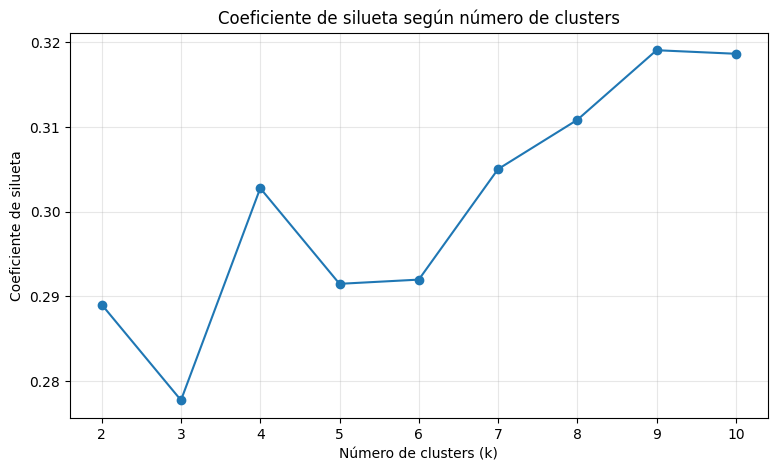

In [55]:
# Calcular el coeficiente de silueta para diferentes valores de k
resultados_silueta = []

for k in valores_k:
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Entrenar con la muestra de 20.000 registros
    etiquetas = modelo_kmeans.fit_predict(X_kmeans_muestra)

    # Calcular silueta sobre una submuestra para reducir el costo
    silueta = silhouette_score(
        X_kmeans_muestra,
        etiquetas,
        sample_size=3000,
        random_state=42
    )

    resultados_silueta.append({
        "Número de clusters": k,
        "Coeficiente de silueta": silueta
    })

# Mostrar resultados ordenados
df_resultados_silueta = pd.DataFrame(resultados_silueta)

display(
    df_resultados_silueta.sort_values(
        "Coeficiente de silueta",
        ascending=False
    ).round(4)
)

# Graficar los resultados
plt.figure(figsize=(9, 5))

plt.plot(
    df_resultados_silueta["Número de clusters"],
    df_resultados_silueta["Coeficiente de silueta"],
    marker="o"
)

plt.title("Coeficiente de silueta según número de clusters")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

**Resultados del coeficiente de silueta y selección del número de clusters**

La evaluación mediante el coeficiente de silueta mostró diferencias en la calidad de los agrupamientos según la cantidad de clusters considerada.

El mayor valor se obtuvo con nueve clusters (0.3191), seguido de diez clusters (0.3187). Sin embargo, los coeficientes obtenidos indican una separación limitada entre los grupos, sin evidenciar una estructura de agrupamiento claramente definida.

Por su parte, el método del codo mostró una reducción pronunciada de la inercia hasta aproximadamente cuatro o cinco clusters, a partir de los cuales las mejoras comenzaron a ser progresivamente menores.

Considerando ambos resultados, se decidió seleccionar **cuatro clusters** como configuración inicial para el análisis exploratorio. Esta alternativa presentó un coeficiente de silueta de 0.3028 y permite trabajar con una cantidad de grupos relativamente reducida, facilitando su posterior caracterización e interpretación.

La elección no representa un óptimo absoluto, sino un compromiso entre la compactación de los grupos, su separación y la interpretabilidad de los resultados.

En consecuencia, se utilizará `k = 4` para el entrenamiento del modelo K-Means, y posteriormente se analizarán las características de los clusters obtenidos para determinar si presentan patrones relevantes de demanda de pasajeros.

#### 9.4 Entrenamiento del modelo K-Means

Una vez seleccionado el número de clusters, se procederá al entrenamiento del algoritmo K-Means utilizando el conjunto completo de registros transformados y escalados.

Se utilizarán cuatro clusters, de acuerdo con los resultados obtenidos mediante el método del codo y el coeficiente de silueta.

El algoritmo asignará cada observación a uno de los cuatro grupos según su proximidad a los centroides, considerando las características seleccionadas: volumen de pasajeros transformado, franja horaria y representación cíclica del día de la semana.

Las etiquetas generadas por K-Means no representan directamente niveles de demanda Baja, Media o Alta. Su significado se establecerá posteriormente mediante el análisis de las características de cada grupo.

In [56]:
# Definir la cantidad de clusters seleccionada
k_seleccionado = 4

# Crear el modelo K-Means
modelo_kmeans_final = KMeans(
    n_clusters=k_seleccionado,
    random_state=42,
    n_init=10
)

# Entrenar y obtener las etiquetas de cada registro
etiquetas_kmeans = modelo_kmeans_final.fit_predict(
    X_kmeans_escalado
)

# Crear una copia para analizar los resultados
df_clusters = df_modelo.copy()

# Incorporar las etiquetas generadas por K-Means
df_clusters["cluster"] = etiquetas_kmeans

# Revisar la cantidad de registros por cluster
print("Cantidad de registros por cluster:")
display(
    df_clusters["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Cantidad de registros")
)

# Mostrar la inercia del modelo final
print(f"\nInercia del modelo final: {modelo_kmeans_final.inertia_:.2f}")

Cantidad de registros por cluster:


,Cluster,Cantidad de registros
0,0,110633
1,1,229484
2,2,158113
3,3,155389



Inercia del modelo final: 1175469.26


**Resultados del entrenamiento de K-Means**

El modelo K-Means fue entrenado utilizando los 653.619 registros del conjunto de datos transformado y escalado, con una configuración de cuatro clusters.

La distribución obtenida fue la siguiente:

| Cluster | Cantidad de registros | Porcentaje |
|---|---:|---:|
| 0 | 110.633 | 16,93 % |
| 1 | 229.484 | 35,11 % |
| 2 | 158.113 | 24,19 % |
| 3 | 155.389 | 23,77 % |
| **Total** | **653.619** | **100 %** |

El cluster 1 concentra la mayor proporción de registros, mientras que el cluster 0 presenta la menor cantidad de observaciones.

La inercia del modelo final fue de 1.175.469,26, correspondiente a la suma de las distancias cuadráticas de las observaciones respecto de sus centroides en el espacio de características escaladas.

Estos resultados confirman que el algoritmo asignó todas las observaciones a uno de los cuatro grupos definidos. Sin embargo, la distribución de registros no permite establecer por sí misma el significado de cada cluster.

Por este motivo, en el siguiente apartado se analizarán las características de los grupos obtenidos, considerando el volumen de pasajeros y las variables temporales utilizadas durante el agrupamiento.

#### 9.5 Caracterización e interpretación de los clusters

Una vez entrenado el modelo K-Means, se analizarán las características de los grupos identificados para determinar si representan patrones diferenciados de demanda de pasajeros.

La interpretación se realizará utilizando las variables originales del conjunto de datos, lo que permitirá expresar los resultados en términos comprensibles y relacionados con el problema de investigación.

Se examinarán principalmente el volumen de pasajeros, las franjas horarias y los días de la semana asociados a cada cluster.

Los grupos serán interpretados a partir de sus características predominantes, sin asumir que sus identificadores corresponden directamente a niveles de demanda Baja, Media o Alta.

##### 9.5.1 Caracterización según el volumen de pasajeros

En primer lugar, se analizará la distribución del volumen de pasajeros en cada cluster, considerando medidas descriptivas como la cantidad de registros, la media, la mediana y los valores mínimos y máximos.

In [57]:
# Calcular estadísticas del volumen de pasajeros por cluster
df_resumen_clusters = (
    df_clusters
    .groupby("cluster")["pax_total"]
    .agg(
        registros="count",
        promedio="mean",
        mediana="median",
        minimo="min",
        maximo="max"
    )
    .round(2)
    .reset_index()
)

# Mostrar el resumen ordenado por cluster
print("Estadísticas de pasajeros por cluster:")
display(df_resumen_clusters)

Estadísticas de pasajeros por cluster:


,cluster,registros,promedio,mediana,minimo,maximo
0,0,110633,35.31,20.0,0.0,751.0
1,1,229484,2686.41,1543.0,2.0,63296.0
2,2,158113,889.78,474.0,0.0,37457.0
3,3,155389,2773.11,1646.0,3.0,51735.0


**Interpretación del volumen de pasajeros por cluster**

El análisis descriptivo permitió identificar diferencias en el volumen de pasajeros entre los cuatro clusters obtenidos mediante K-Means.

El **cluster 0** presenta los valores más bajos de demanda, con un promedio de 35,31 pasajeros y una mediana de 20, lo que permite caracterizarlo como un grupo de registros de volumen muy reducido.

Por su parte, el **cluster 2** presenta valores intermedios, con un promedio de 889,78 pasajeros y una mediana de 474.

Los **clusters 1 y 3** concentran registros con volúmenes relativamente elevados. El cluster 1 presenta un promedio de 2.686,41 pasajeros y una mediana de 1.543, mientras que el cluster 3 alcanza un promedio de 2.773,11 y una mediana de 1.646.

La similitud entre los volúmenes de pasajeros de estos últimos dos grupos sugiere que su diferenciación podría estar relacionada con las características temporales utilizadas durante el agrupamiento.

Asimismo, las diferencias entre los promedios y las medianas, junto con los valores máximos observados, evidencian distribuciones asimétricas y la presencia de registros con volúmenes elevados.

Estos resultados permiten realizar una primera caracterización de los clusters según la demanda, aunque todavía es necesario analizar las franjas horarias y los días de la semana para comprender mejor los patrones identificados.

##### 9.5.2 Caracterización según la franja horaria

Con el objetivo de profundizar en la interpretación de los agrupamientos, se analizará la distribución de las franjas horarias dentro de cada cluster.

Este análisis permitirá identificar si determinados grupos concentran una mayor proporción de registros en franjas específicas y si las características temporales contribuyen a explicar las diferencias observadas entre clusters con volúmenes de pasajeros similares.

Los resultados se expresarán como porcentajes respecto del total de registros de cada cluster, facilitando su comparación independientemente del tamaño de los grupos.

In [58]:
# Contar los registros por cluster y franja horaria
tabla_franjas = pd.crosstab(
    df_clusters["cluster"],
    df_clusters["franja_horaria_num"],
    normalize="index"
) * 100

# Redondear los porcentajes
tabla_franjas = tabla_franjas.round(2)

print("Distribución porcentual de franjas horarias por cluster:")
display(tabla_franjas)

Distribución porcentual de franjas horarias por cluster:


franja_horaria_num,1,2,3,4,5
cluster,,,,,
0,90.63,7.54,1.10,0.38,0.35
1,0.21,23.77,25.71,25.66,24.65
2,0.09,23.66,24.83,24.98,26.44
3,0.26,24.33,25.28,25.17,24.96


**Interpretación de la distribución por franja horaria**

El análisis de las franjas horarias permitió identificar diferencias importantes entre los agrupamientos obtenidos.

El **cluster 0** presenta una marcada concentración en la franja horaria 1, que representa el 90,63 % de sus registros. Este resultado, junto con su bajo volumen de pasajeros, permite caracterizarlo como un grupo asociado principalmente a registros de demanda muy reducida en dicha franja.

Por otro lado, los **clusters 1, 2 y 3** presentan distribuciones similares, con porcentajes relativamente equilibrados entre las franjas horarias 2, 3, 4 y 5.

En consecuencia, la franja horaria parece contribuir especialmente a la diferenciación del cluster 0, pero no permite explicar completamente la separación entre los demás grupos.

En particular, los clusters 1 y 3, que presentan volúmenes de pasajeros similares, también muestran distribuciones horarias semejantes.

Por este motivo, resulta necesario analizar el comportamiento semanal de los registros para determinar si existen diferencias relacionadas con el día de la semana que contribuyan a caracterizar estos agrupamientos.

##### 9.5.3 Caracterización según el día de la semana

Para complementar la caracterización de los clusters, se analizará la distribución de los registros según el día de la semana.

Este análisis permitirá identificar si los agrupamientos presentan patrones temporales diferenciados, particularmente entre días laborales y fines de semana.

Se calculará la distribución porcentual de los siete días dentro de cada cluster, utilizando la variable original dia_semana.

Los resultados permitirán evaluar si el comportamiento semanal contribuye a explicar las diferencias observadas entre los clusters, especialmente entre aquellos que presentan volúmenes de pasajeros y distribuciones horarias similares.

In [59]:
# Calcular la distribución porcentual de días por cluster
tabla_dias = pd.crosstab(
    df_clusters["cluster"],
    df_clusters["dia_semana"],
    normalize="index"
) * 100

# Asignar nombres a los días de la semana
tabla_dias.columns = [
    "Lunes",
    "Martes",
    "Miércoles",
    "Jueves",
    "Viernes",
    "Sábado",
    "Domingo"
]

# Mostrar los resultados redondeados
print("Distribución porcentual de días de la semana por cluster:")
display(tabla_dias.round(2))

Distribución porcentual de días de la semana por cluster:


,Lunes,Martes,Miércoles,Jueves,Viernes,Sábado,Domingo
cluster,,,,,,,
0,17.13,17.41,18.59,17.85,16.98,8.44,3.60
1,32.42,33.84,33.74,0.00,0.00,0.00,0.00
2,1.58,0.00,0.00,0.00,0.17,49.60,48.64
3,0.00,0.00,0.00,50.08,49.92,0.00,0.00


**Interpretación de la distribución por día de la semana**

El análisis de la distribución semanal permitió identificar patrones temporales claramente diferenciados entre los cuatro clusters obtenidos mediante K-Means.

El **cluster 0** presenta una mayor concentración de registros durante los días laborales, aunque también incluye observaciones correspondientes al fin de semana. Su principal característica continúa siendo el volumen muy reducido de pasajeros y su asociación con la franja horaria 1.

El **cluster 1** agrupa exclusivamente registros correspondientes a lunes, martes y miércoles, con una distribución relativamente equilibrada entre estos tres días. Este grupo presenta volúmenes de pasajeros elevados en comparación con los clusters 0 y 2.

El **cluster 2** concentra principalmente registros de sábado (49,60 %) y domingo (48,64 %), lo que permite caracterizarlo como un agrupamiento asociado al fin de semana. Además, presenta un volumen de pasajeros inferior al de los clusters 1 y 3.

Por último, el **cluster 3** está compuesto por registros de jueves (50,08 %) y viernes (49,92 %). Sus valores de demanda son similares a los del cluster 1, pero su distribución semanal es diferente.

Estos resultados permiten comprender mejor la separación entre los clusters 1 y 3, que presentaban volúmenes de pasajeros y distribuciones horarias semejantes.

En conjunto, el análisis muestra que los agrupamientos identificados combinan características del volumen de pasajeros con patrones temporales relacionados con la franja horaria y el día de la semana.

No obstante, dado que estas variables fueron utilizadas durante el entrenamiento, las diferencias observadas describen la estructura encontrada por el algoritmo y no constituyen una validación independiente de los clusters.

##### 9.5.4 Síntesis de los perfiles identificados

A partir de los análisis anteriores, se elaborará una síntesis de las principales características de cada cluster.

Para ello, se considerarán la cantidad de registros, la mediana de pasajeros y las distribuciones temporales predominantes.

Esta caracterización permitirá identificar los patrones más representativos de cada agrupamiento y facilitará su comparación con los niveles de demanda definidos durante el análisis supervisado.

Los perfiles resultantes tendrán un carácter descriptivo y exploratorio, sin representar necesariamente categorías equivalentes a los niveles de congestión.

In [60]:
# Resumir las características principales de cada cluster
resumen_perfiles = (
    df_clusters.groupby("cluster")
    .agg(
        registros=("pax_total", "size"),
        promedio_pasajeros=("pax_total", "mean"),
        mediana_pasajeros=("pax_total", "median"),
        franja_predominante=(
            "franja_horaria_num",
            lambda x: x.mode().iloc[0]
        ),
        dia_predominante=(
            "dia_semana",
            lambda x: x.mode().iloc[0]
        )
    )
    .reset_index()
)

# Traducir los números de los días
nombres_dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

resumen_perfiles["dia_predominante"] = (
    resumen_perfiles["dia_predominante"].map(nombres_dias)
)

# Mostrar el resumen
print("Resumen de perfiles por cluster:")
display(resumen_perfiles.round(2))

Resumen de perfiles por cluster:


,cluster,registros,promedio_pasajeros,mediana_pasajeros,franja_predominante,dia_predominante
0,0,110633,35.31,20.0,1,Miércoles
1,1,229484,2686.41,1543.0,3,Martes
2,2,158113,889.78,474.0,5,Sábado
3,3,155389,2773.11,1646.0,3,Jueves


#### 9.6 Relación entre los clusters y los niveles de demanda

Con el objetivo de complementar la interpretación del análisis no supervisado, se compararán los clusters obtenidos mediante K-Means con los niveles de demanda definidos anteriormente para los modelos de clasificación supervisada.

Mientras que K-Means identifica agrupaciones a partir de la similitud entre las características de los registros, las categorías Baja, Media y Alta fueron construidas mediante umbrales estadísticos aplicados al volumen de pasajeros.

Esta comparación permitirá analizar cómo se distribuyen los niveles de demanda dentro de cada cluster y determinar si los agrupamientos identificados presentan alguna correspondencia con las categorías previamente establecidas.

Es importante señalar que los niveles de demanda no fueron utilizados durante el entrenamiento de K-Means. Por lo tanto, su incorporación en esta etapa tendrá únicamente una finalidad descriptiva.

Asimismo, dado que pax_total fue una de las características utilizadas para construir los clusters y también determina las categorías de demanda, las posibles correspondencias deberán interpretarse con cautela, ya que ambas representaciones comparten información.

##### 9.6.1 Comparación de clusters con las categorías de demanda

Se calculará la distribución porcentual de las categorías Baja, Media y Alta dentro de cada cluster, utilizando los mismos umbrales definidos durante la etapa de ajuste y validación temporal de los modelos supervisados.

In [61]:
# Crear una copia para comparar clusters y niveles de demanda
df_comparacion_clusters = df_clusters.copy()

# Aplicar los umbrales definidos en el Punto 8
# Estos umbrales se calcularon con datos de 2017-2019
df_comparacion_clusters["nivel_demanda"] = pd.cut(
    df_comparacion_clusters["pax_total"],
    bins=[-np.inf, umbral_bajo_ajuste, umbral_alto_ajuste, np.inf],
    labels=["Baja", "Media", "Alta"],
    right=True
)

# Calcular la distribución porcentual por cluster
tabla_demanda_clusters = pd.crosstab(
    df_comparacion_clusters["cluster"],
    df_comparacion_clusters["nivel_demanda"],
    normalize="index"
) * 100

# Mostrar la tabla de resultados
print("Distribución porcentual de niveles de demanda por cluster:")
display(tabla_demanda_clusters.round(2))

# Verificar que cada cluster sume aproximadamente 100 %
print("\nTotal porcentual por cluster:")
display(tabla_demanda_clusters.sum(axis=1).round(2))

Distribución porcentual de niveles de demanda por cluster:


nivel_demanda,Baja,Media,Alta
cluster,,,
0,99.99,0.01,0.00
1,21.60,38.59,39.81
2,52.18,38.01,9.81
3,20.09,38.38,41.53



Total porcentual por cluster:


,0
cluster,
0,100.0
1,100.0
2,100.0
3,100.0


**Interpretación de la relación entre clusters y niveles de demanda**

La comparación entre los clusters obtenidos mediante K-Means y las categorías de demanda permitió identificar diferencias relevantes en la composición de los agrupamientos.

El **cluster 0** presenta una correspondencia casi total con la categoría Baja, que representa el 99,99 % de sus registros. Este resultado es consistente con el reducido volumen de pasajeros y la concentración en la franja horaria 1 observados anteriormente.

El **cluster 2** presenta un predominio de demanda Baja (52,18 %), seguido de Media (38,01 %) y una proporción menor de Alta (9,81 %). Este agrupamiento se encuentra asociado principalmente a registros de fines de semana.

Por su parte, los **clusters 1 y 3** muestran composiciones similares, con una mayor participación conjunta de las categorías Media y Alta. En el cluster 1, estas categorías representan el 38,59 % y el 39,81 %, respectivamente, mientras que en el cluster 3 alcanzan el 38,38 % y el 41,53 %.

La principal diferencia entre estos dos últimos grupos se encuentra en su distribución semanal: el cluster 1 concentra registros de lunes a miércoles, mientras que el cluster 3 agrupa registros de jueves y viernes.

En conjunto, los resultados muestran que K-Means identificó agrupamientos que combinan diferencias en el volumen de pasajeros con patrones temporales específicos.

Sin embargo, la correspondencia observada debe interpretarse con cautela, debido a que el volumen de pasajeros fue utilizado tanto para construir los clusters como para definir las categorías de demanda. Por lo tanto, esta comparación constituye un análisis descriptivo complementario y no una validación independiente del algoritmo.

##### 9.6.2 Conclusiones del análisis de agrupamiento

La aplicación del algoritmo K-Means permitió explorar patrones de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021, utilizando características relacionadas con el volumen de pasajeros, la franja horaria y el día de la semana.

A partir de la evaluación del método del codo y el coeficiente de silueta, se seleccionó una configuración de cuatro clusters, priorizando un equilibrio entre la compactación, la separación y la interpretabilidad de los agrupamientos.

El análisis permitió identificar cuatro perfiles principales:

- **Cluster 0:** registros de volumen muy bajo, asociados principalmente a la franja horaria 1.
- **Cluster 1:** registros de lunes a miércoles, con una participación importante de demanda Media y Alta.
- **Cluster 2:** registros predominantemente de fines de semana, con mayor presencia de demanda Baja y Media.
- **Cluster 3:** registros de jueves y viernes, con una participación importante de demanda Media y Alta.

Estos resultados muestran que los agrupamientos no se organizan exclusivamente según la cantidad de pasajeros, sino también a partir de las características temporales de los registros.

En particular, los clusters 1 y 3 presentan volúmenes de pasajeros similares, pero se diferencian por los días de la semana que los integran. Esto permite reconocer patrones temporales que no resultan evidentes al analizar únicamente las categorías de demanda.

La comparación con los niveles Baja, Media y Alta permitió complementar la interpretación de los grupos identificados. No obstante, esta relación debe considerarse descriptiva, ya que ambas representaciones utilizan información del volumen de pasajeros.

Asimismo, los coeficientes de silueta obtenidos indican que la separación entre los grupos es limitada, por lo que los clusters no deben interpretarse como categorías definitivas de comportamiento o congestión.

En relación con los modelos supervisados, K-Means aporta una perspectiva exploratoria complementaria: mientras que Regresión Logística y Random Forest buscaron predecir niveles de demanda previamente definidos, el análisis no supervisado permitió describir agrupaciones de registros con características similares.

En conclusión, el análisis de agrupamiento contribuyó al diagnóstico de los patrones de demanda de pasajeros, aunque sus resultados deben interpretarse considerando las variables seleccionadas, las transformaciones realizadas y las limitaciones propias del conjunto de datos.

#### 10. Discusión de resultados y conclusiones generales

El presente trabajo tuvo como objetivo analizar los patrones de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021 y desarrollar modelos que permitieran clasificar sus niveles de demanda.

Para ello, se trabajó con un conjunto histórico de 653.619 registros procesados, integrando técnicas de análisis exploratorio, clasificación supervisada y agrupamiento no supervisado.

Los resultados obtenidos permitieron identificar características temporales de la demanda, evaluar diferentes alternativas de modelado y reconocer las principales limitaciones asociadas con la predicción de los niveles de pasajeros.

#### 10.1 Discusión de los resultados del modelado supervisado

En la etapa de clasificación supervisada se utilizaron los algoritmos Regresión Logística y Random Forest para predecir tres categorías de demanda: Baja, Media y Alta.

Estas categorías fueron construidas a partir de umbrales estadísticos aplicados al volumen de pasajeros. Durante la etapa de ajuste y validación temporal, los umbrales se calcularon utilizando exclusivamente los registros de entrenamiento correspondientes a 2017–2019.

La estrategia de validación contempló tres períodos: entrenamiento con datos de 2017–2019, validación sobre 2020 y evaluación final sobre 2021.

Durante la validación, Random Forest obtuvo mejores resultados que Regresión Logística, alcanzando un F1-score macro de 0.4225 frente a 0.4036. Por este motivo, se seleccionó Random Forest como modelo principal.

Posteriormente, el modelo fue reentrenado con registros de 2017–2020 y evaluado sobre 2021, obteniendo los siguientes resultados:

| Métrica | Resultado |
|---|---:|
| Accuracy | 0.5825 |
| F1-score macro | 0.3999 |
| Recall de demanda Baja | 0.90 |
| Recall de demanda Media | 0.18 |
| Recall de demanda Alta | 0.16 |

Los resultados muestran que el modelo presentó una mayor capacidad para identificar registros de demanda Baja, pero tuvo dificultades importantes para reconocer las categorías Media y Alta.

En particular, el bajo recall de demanda Alta constituye una limitación relevante, ya que uno de los intereses de la investigación es identificar situaciones de elevada demanda de pasajeros.

Asimismo, la comparación temporal mostró diferencias considerables entre el desempeño del modelo durante la validación de 2020 y la evaluación de 2021.

Aunque el Accuracy aumentó de 0.4455 a 0.5825, el F1-score macro disminuyó de 0.4225 a 0.3999. Además, el recall de demanda Alta pasó de aproximadamente 0.91 a 0.16.

Estas diferencias evidencian que una mejora en la exactitud general no necesariamente implica una mayor capacidad para identificar todas las categorías de demanda.

No obstante, esta comparación debe interpretarse considerando que los modelos fueron entrenados con diferentes períodos históricos y que las distribuciones de demanda también variaron entre los años evaluados.

En consecuencia, los resultados permiten considerar a Random Forest como la alternativa con mejor desempeño comparativo durante la validación, aunque su capacidad de generalización temporal resultó limitada.

#### 10.2 Aportes del análisis no supervisado y limitaciones

Como complemento del modelado supervisado, se aplicó K-Means para identificar agrupaciones de registros con características similares.

Se utilizaron variables relacionadas con el volumen de pasajeros, la franja horaria y el día de la semana. Previamente, se realizaron transformaciones y procedimientos de escalado para preparar los datos.

Mediante el método del codo y el coeficiente de silueta se evaluaron diferentes cantidades de clusters, seleccionándose cuatro grupos como configuración inicial por su equilibrio entre compactación, separación e interpretabilidad.

El análisis permitió identificar los siguientes perfiles:

| **Cluster** | **Características principales** |
|---|---|
| 0 | Registros de volumen muy bajo, asociados principalmente a la franja horaria 1 |
| 1 | Registros de lunes a miércoles, con presencia importante de demanda Media y Alta |
| 2 | Registros principalmente de fines de semana, con predominio de demanda Baja y Media |
| 3 | Registros de jueves y viernes, con presencia importante de demanda Media y Alta |

Uno de los resultados más relevantes fue la identificación de dos agrupamientos con volúmenes de pasajeros similares, correspondientes a los clusters 1 y 3, pero diferenciados por su distribución semanal.

Esto permitió observar que los patrones de demanda no dependen únicamente del volumen de pasajeros, sino que también presentan características temporales específicas.

La comparación posterior con las categorías Baja, Media y Alta permitió describir la composición de cada grupo. Sin embargo, esta correspondencia no constituye una validación independiente, ya que el volumen de pasajeros fue utilizado tanto para construir las categorías como para entrenar K-Means.

Asimismo, los coeficientes de silueta obtenidos mostraron una separación limitada entre los agrupamientos, por lo que los clusters deben considerarse perfiles exploratorios y no categorías definitivas.

#### Limitaciones del estudio

Los resultados deben interpretarse considerando las siguientes limitaciones:

- **Medición indirecta de congestión:** se utilizó el volumen de pasajeros como aproximación a la demanda y a posibles situaciones de congestión. Sin embargo, no se dispuso de mediciones directas de ocupación, capacidad de los trenes o densidad de pasajeros.

- **Período de análisis:** los años 2020 y 2021 estuvieron afectados por alteraciones extraordinarias en los patrones de movilidad, lo que puede haber influido en la distribución de la demanda y en el desempeño de los modelos.

- **Disponibilidad de variables:** no se incorporaron factores externos, como condiciones meteorológicas, feriados, frecuencia del servicio o interrupciones operativas.

- **Calidad y cobertura de los datos:** el procesamiento histórico requirió tareas de limpieza y normalización. Las inconsistencias presentes en las fuentes originales pueden afectar la cobertura temporal del análisis.

- **Generalización temporal:** los resultados del modelo supervisado evidenciaron dificultades para mantener un desempeño equilibrado entre categorías en diferentes períodos.

- **Alcance del agrupamiento:** los clusters dependen de las variables seleccionadas, sus transformaciones y la cantidad de grupos definida.

- **Exploración previa del conjunto de prueba:** durante el desarrollo inicial de los modelos supervisados se analizaron resultados correspondientes a 2021. Posteriormente, este mismo período se utilizó para la evaluación final del modelo seleccionado. Por lo tanto, aunque el ajuste de hiperparámetros se realizó utilizando los datos de entrenamiento y validación, el conjunto de prueba no permaneció completamente independiente de todas las decisiones exploratorias del estudio. Esta situación debe considerarse al interpretar los resultados de generalización temporal.

Estas limitaciones no invalidan el análisis realizado, pero establecen el alcance de las conclusiones y permiten identificar oportunidades de mejora.

#### 10.3 Conclusiones generales y posibles mejoras

El desarrollo de este trabajo permitió analizar los patrones de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021, utilizando técnicas de procesamiento de datos y aprendizaje automático.

En relación con los objetivos planteados, se logró desarrollar una aproximación cuantitativa al diagnóstico de la demanda y construir modelos supervisados para clasificar los registros en tres niveles: Baja, Media y Alta.

Sin embargo, los resultados evidenciaron limitaciones en la capacidad predictiva de los modelos, especialmente para identificar las categorías Media y Alta al evaluar su desempeño sobre períodos posteriores al entrenamiento. Esto demuestra la importancia de considerar los cambios temporales en el comportamiento de los pasajeros y de no evaluar los modelos únicamente a partir de su exactitud general.

Por su parte, el análisis mediante K-Means permitió reconocer agrupamientos asociados tanto al volumen de pasajeros como a las características temporales de los registros, aportando una perspectiva complementaria al diagnóstico.

En conjunto, ambos enfoques contribuyeron a comprender diferentes aspectos del comportamiento de la demanda: los modelos supervisados permitieron evaluar su capacidad de clasificación, mientras que el agrupamiento no supervisado facilitó la identificación de perfiles exploratorios.

Como posibles líneas de mejora, se propone ampliar el conjunto de variables explicativas, incorporar información operativa y contextual, evaluar estrategias adicionales de validación temporal y explorar alternativas de modelado que permitan mejorar la identificación de niveles elevados de demanda.

También resultaría conveniente incorporar indicadores directos de ocupación, capacidad de los trenes o densidad de pasajeros, para establecer una relación más precisa entre la demanda observada y las condiciones reales de congestión.

En conclusión, la investigación permitió avanzar en el diagnóstico y la clasificación de la demanda de pasajeros, identificar patrones temporales relevantes y reconocer las principales limitaciones de los modelos predictivos evaluados.

Si bien los resultados no permiten afirmar que se haya desarrollado un modelo confiable para predecir situaciones reales de congestión, constituyen una base exploratoria para futuras investigaciones orientadas a comprender la evolución de la demanda y mejorar las herramientas de análisis del transporte público urbano.